# Visualization - Weapon Fire activity related Spatio-temporal occupancy maps (fire-STOMs) 
# For any one match 
- Spatiol map evolution vs. epochs (10s)
- Collapsed aggregated evolution vs. epochs
- Collapsed differntiated evolution vs. epochs
  



--- Available Matches ---
[0] 15e5721a-37c8-49c5-a7c9-a1ffb3d03177.csv
[1] 4dfe2ff5-91f6-4ae2-83d7-58754279dc9b.csv
[2] 06d0b143-20af-4c15-9516-11d4f2b131ce.csv
[3] dfae2129-8e6d-4313-a935-a01e28cdbc23.csv
[4] 0e23e716-466b-486b-910a-21d690041f87.csv
[5] 5011d26d-215f-4442-bd46-62db0ed9750a.csv
[6] 366569aa-8bed-4f98-8e36-8e781a02d840.csv
[7] 6d368f91-adab-427f-af28-62a73d9131e1.csv
[8] b675d8f9-0847-4e5e-bea2-8eb71f64fa00.csv
[9] 99a5dfe7-dea3-4e07-b59c-3d3306beb7ff.csv
[10] 2eaffb15-e465-49d9-a429-f3da4d268876.csv
[11] bfed173a-7f65-49a3-91e5-51797f8f7d47.csv
[12] 07d999ab-f33a-4258-ad94-5d914711e9a3.csv
[13] b5b8bf82-55f3-4c7d-a60e-9bcc85b773bd.csv
[14] a13f44cc-0ced-4d3e-871a-888f33c00fac.csv
[15] 902f6036-8868-46b3-83f1-7454993a2f0d.csv
[16] 993c4557-bf47-45ca-b4a5-5a2fbb2fef7c.csv
[17] f3aa02f9-c157-4934-a40d-6a4f5049e22b.csv
[18] 3c99ba44-c785-4b06-86e1-846b3ef70449.csv
[19] 92592618-b905-47cb-b9af-932990bd927c.csv
[20] 4203b7bb-887f-424d-9d27-d527d251f5a7.csv
[21] 885a0f7e-a8e


Enter the index [0 to 277] of the match to visualize:  45



Loading data from: f1fd3a6f-7ac7-4f4d-beb0-279b85d3717c.csv


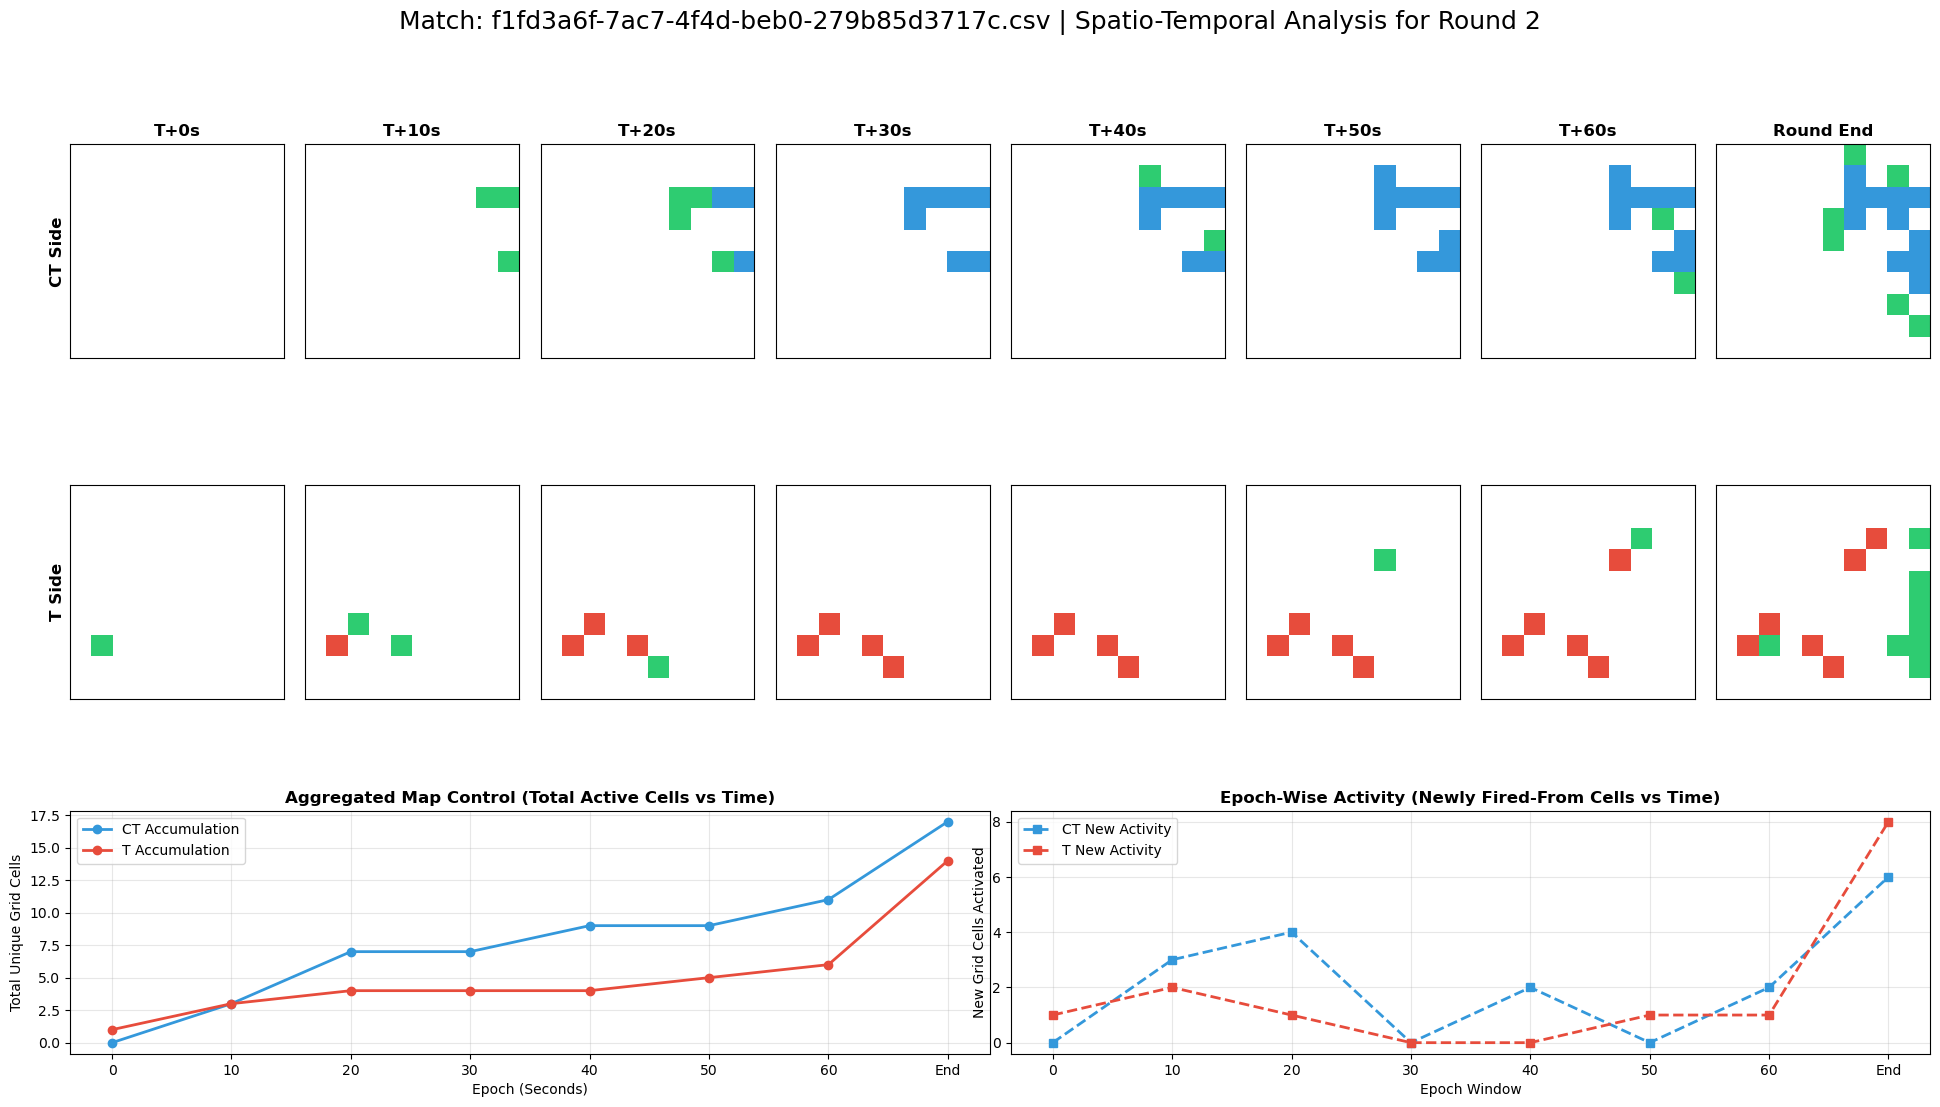

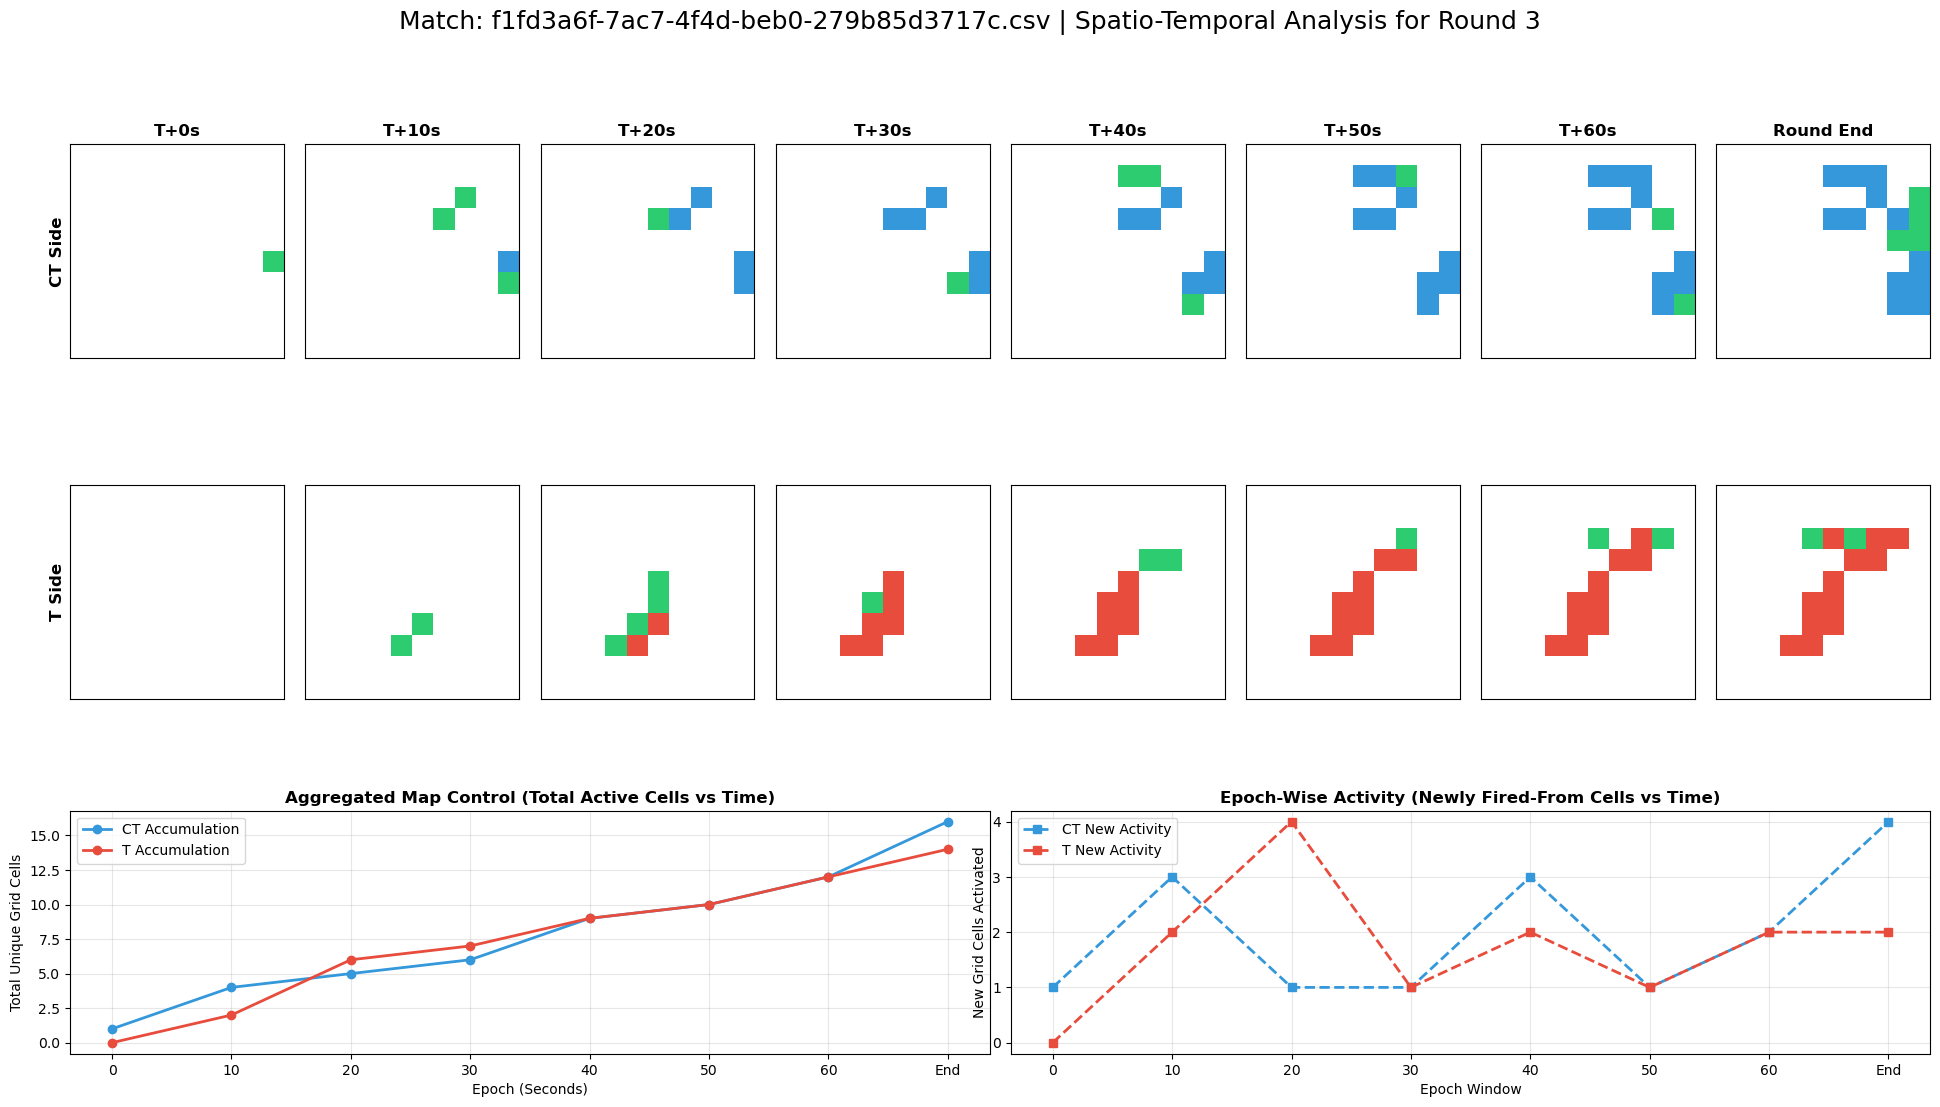

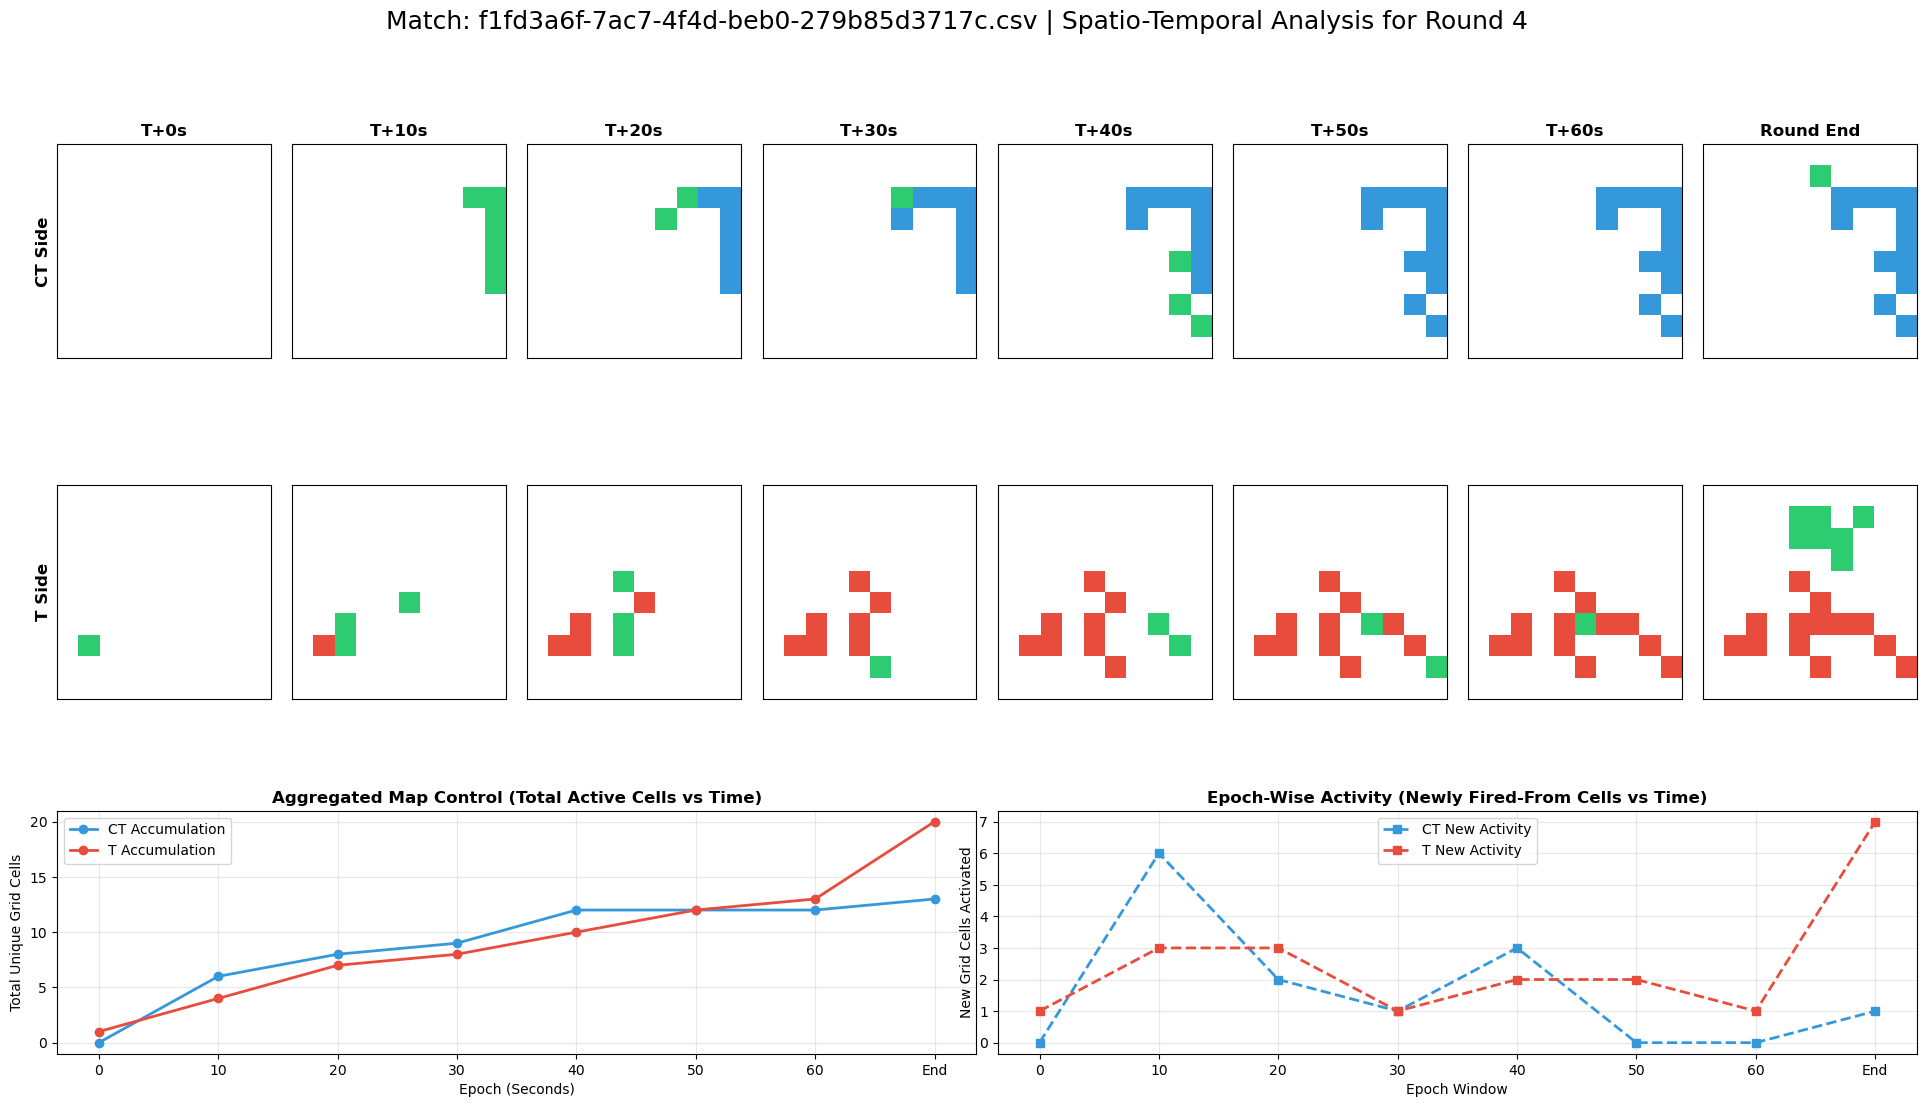

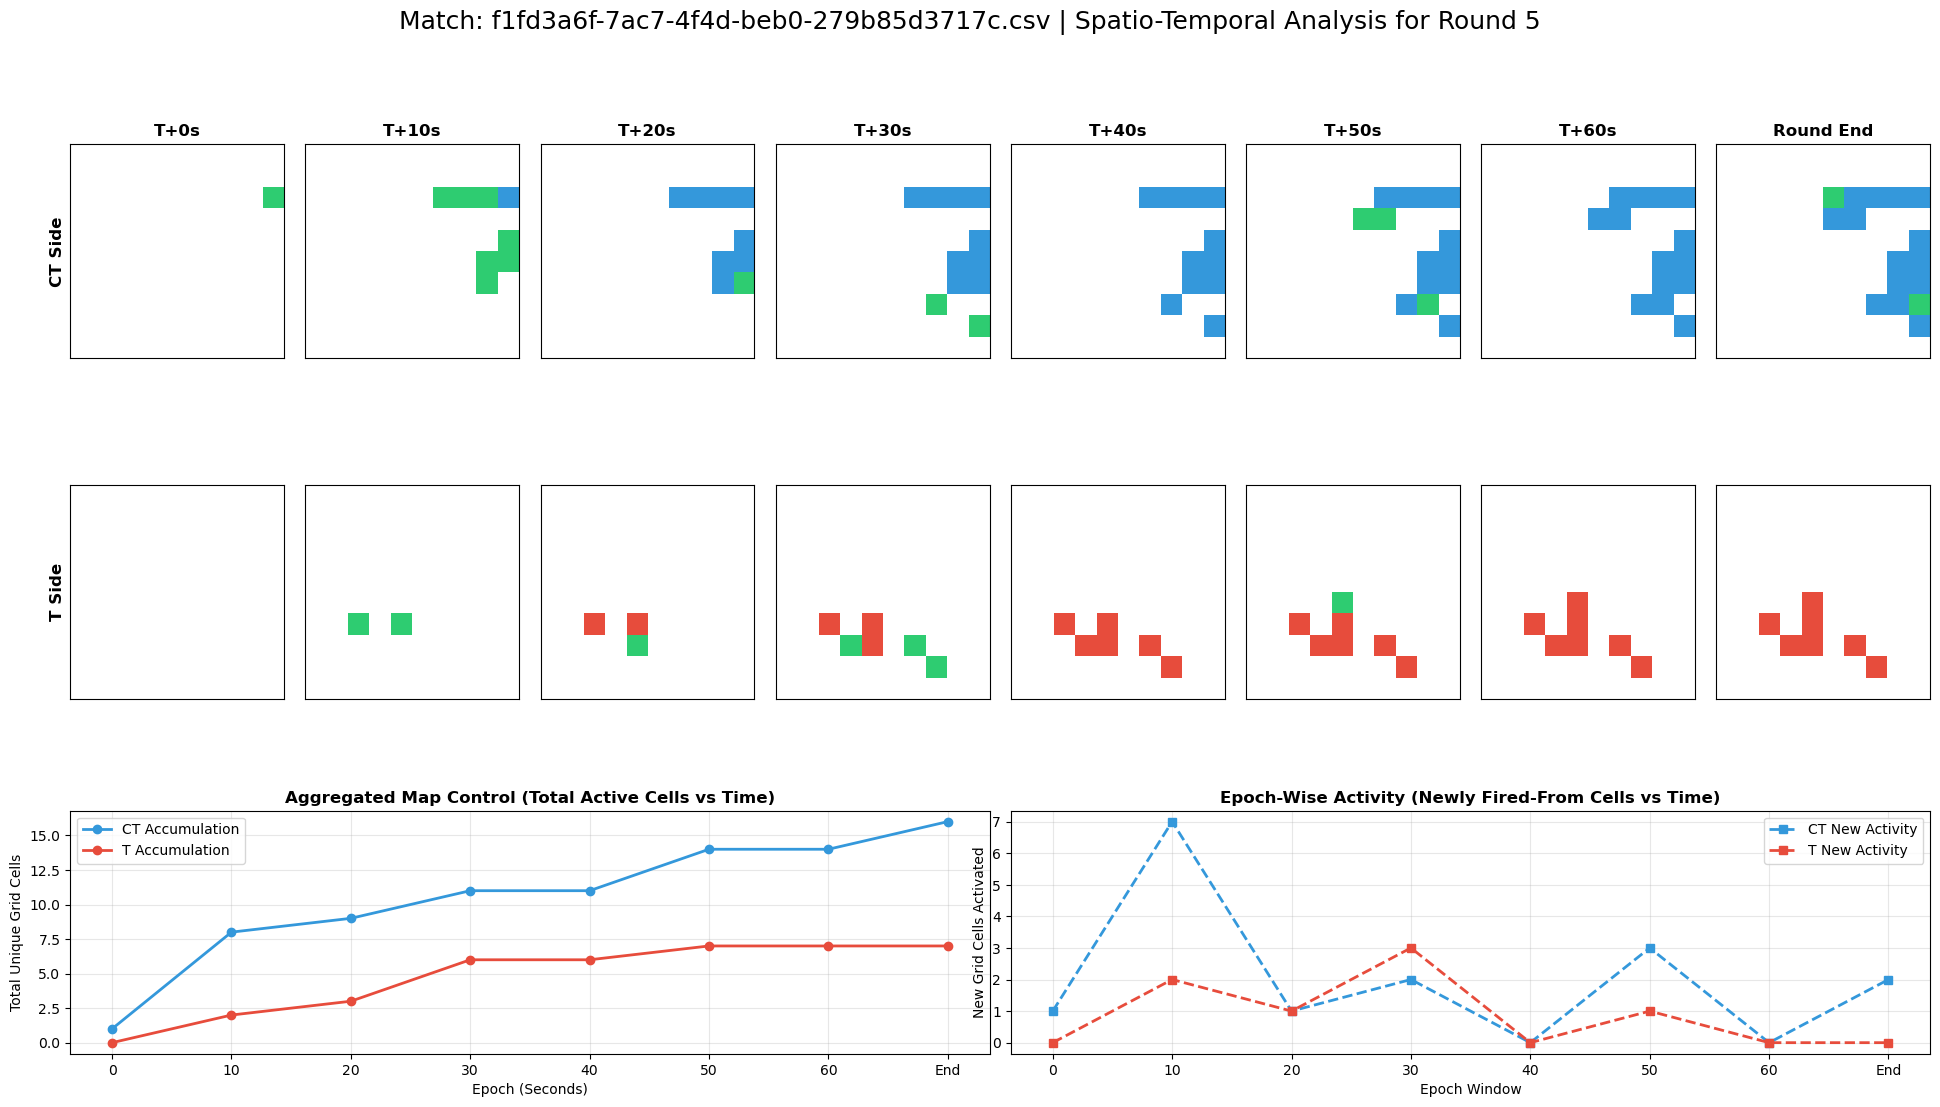

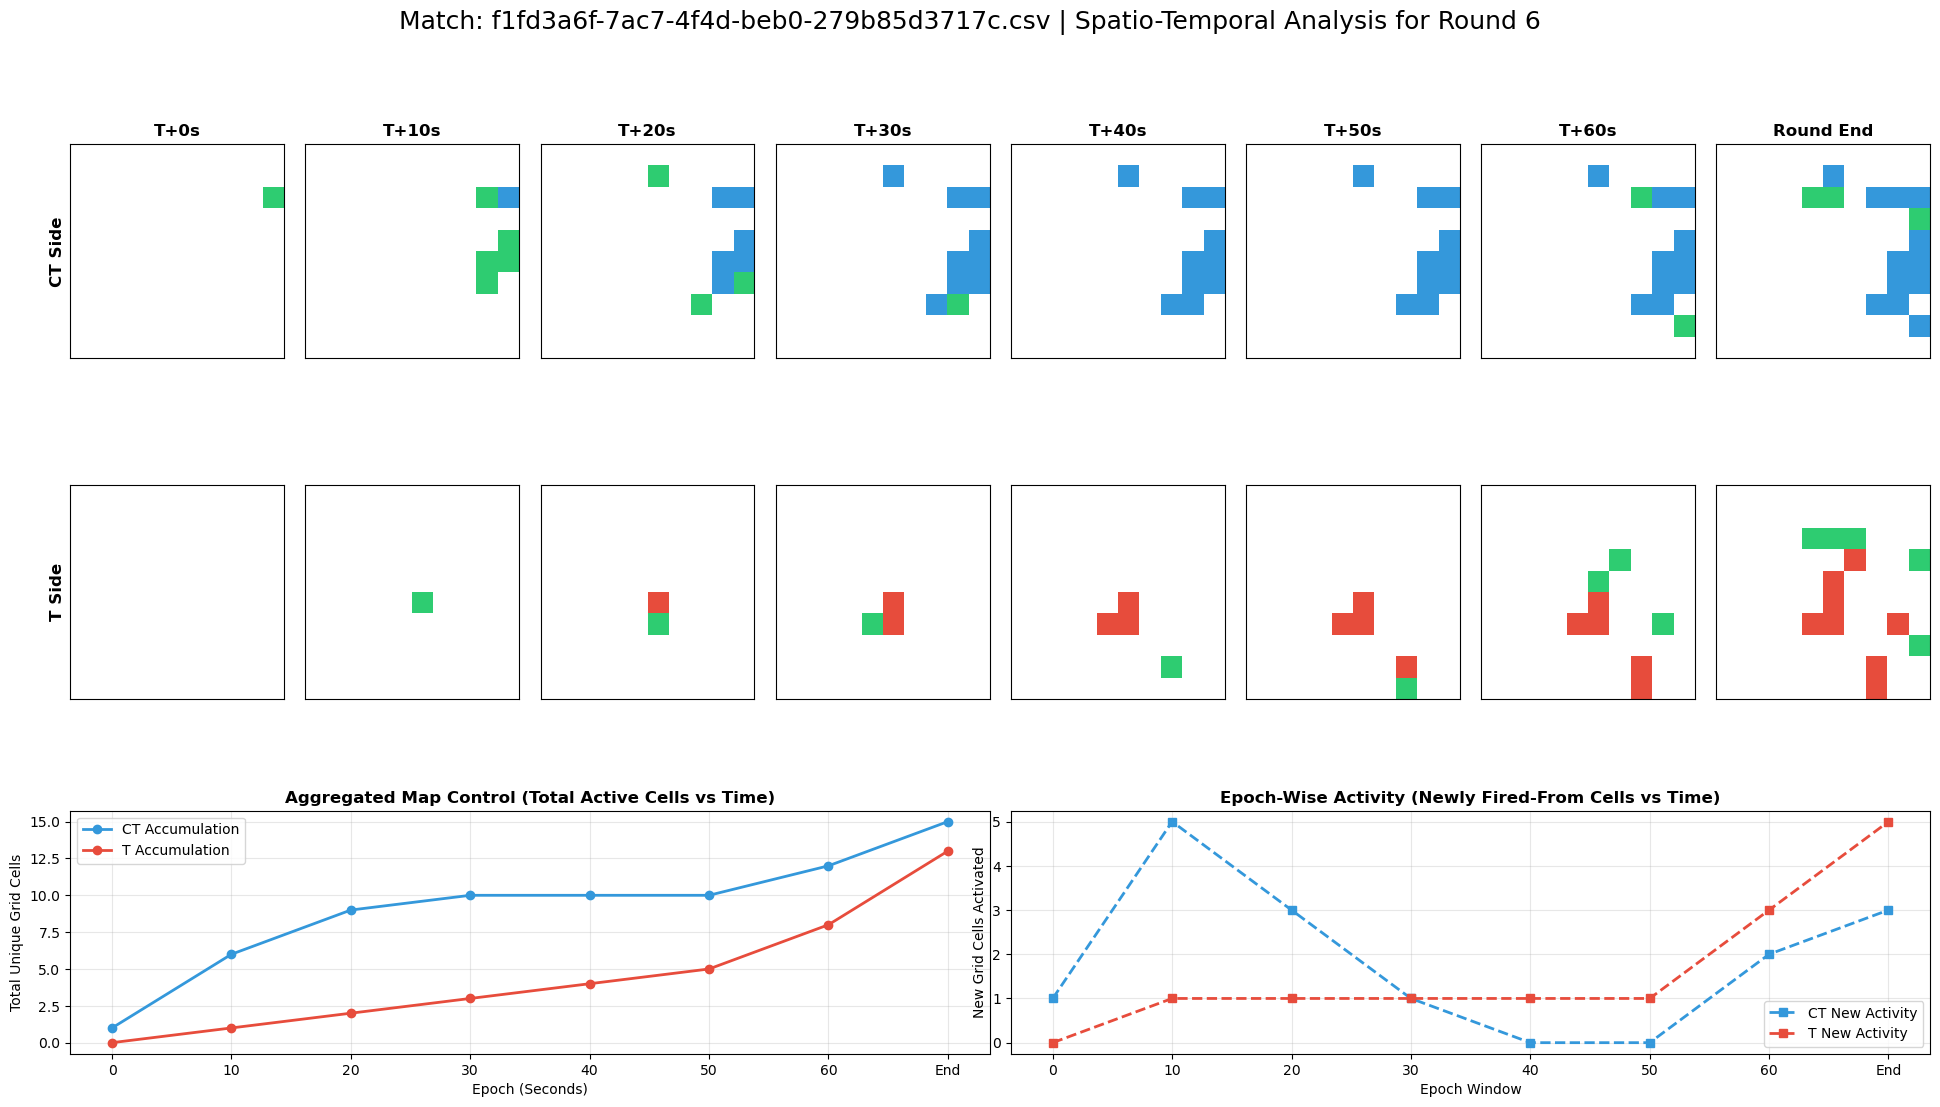

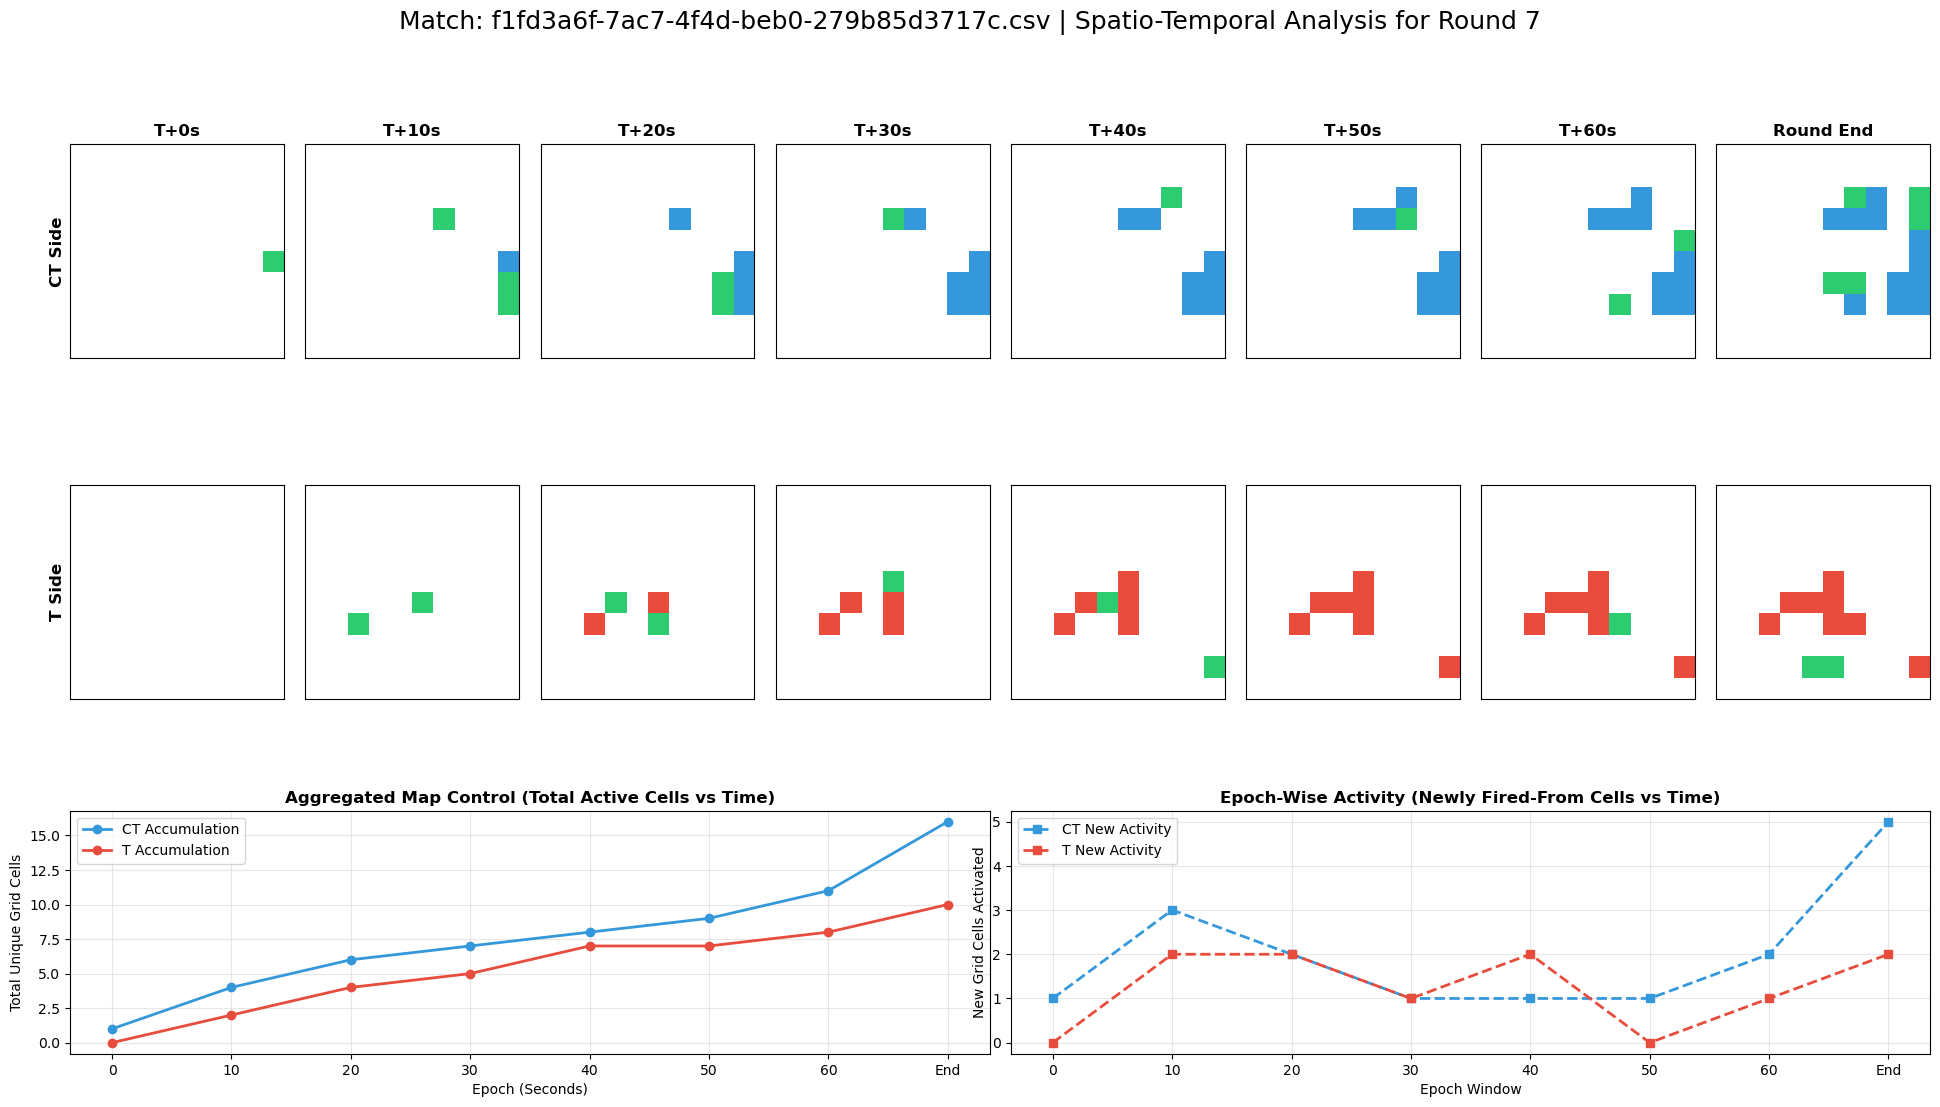

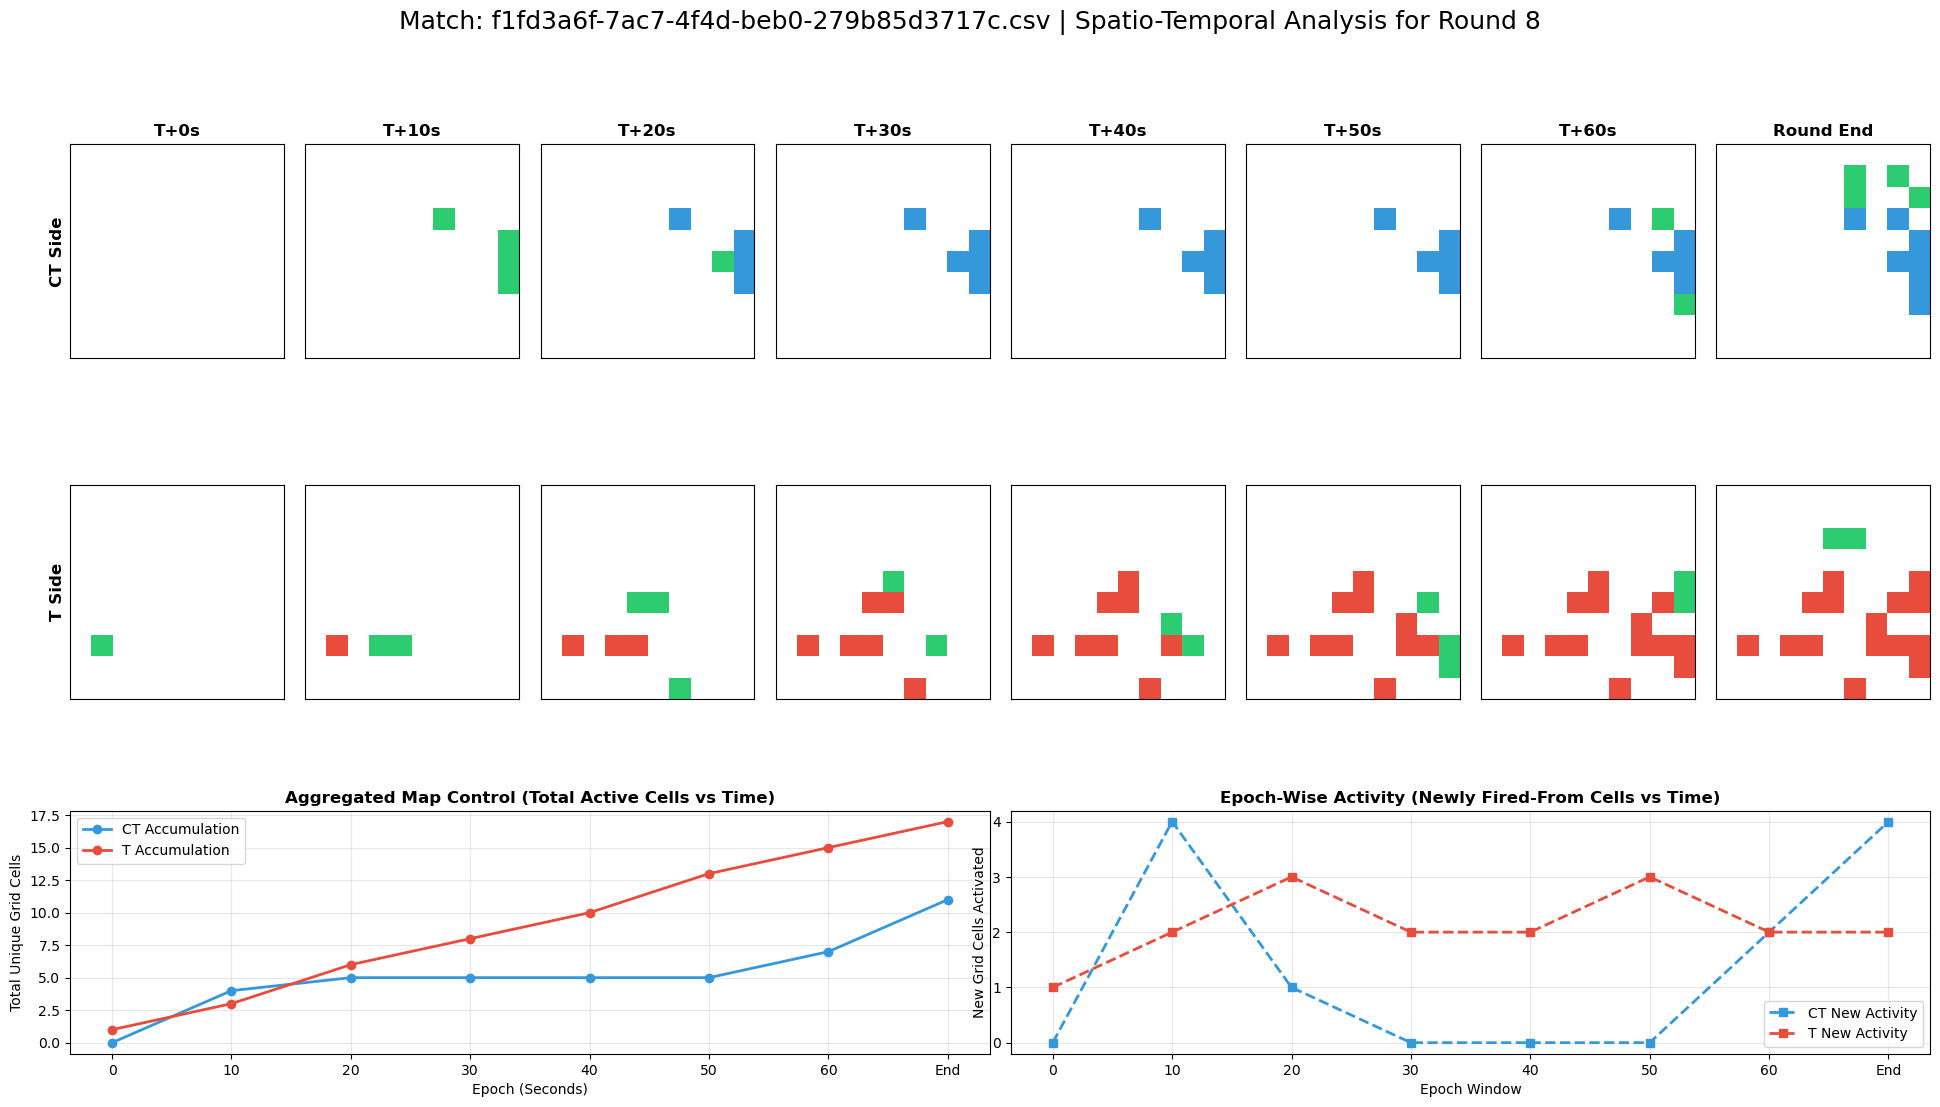

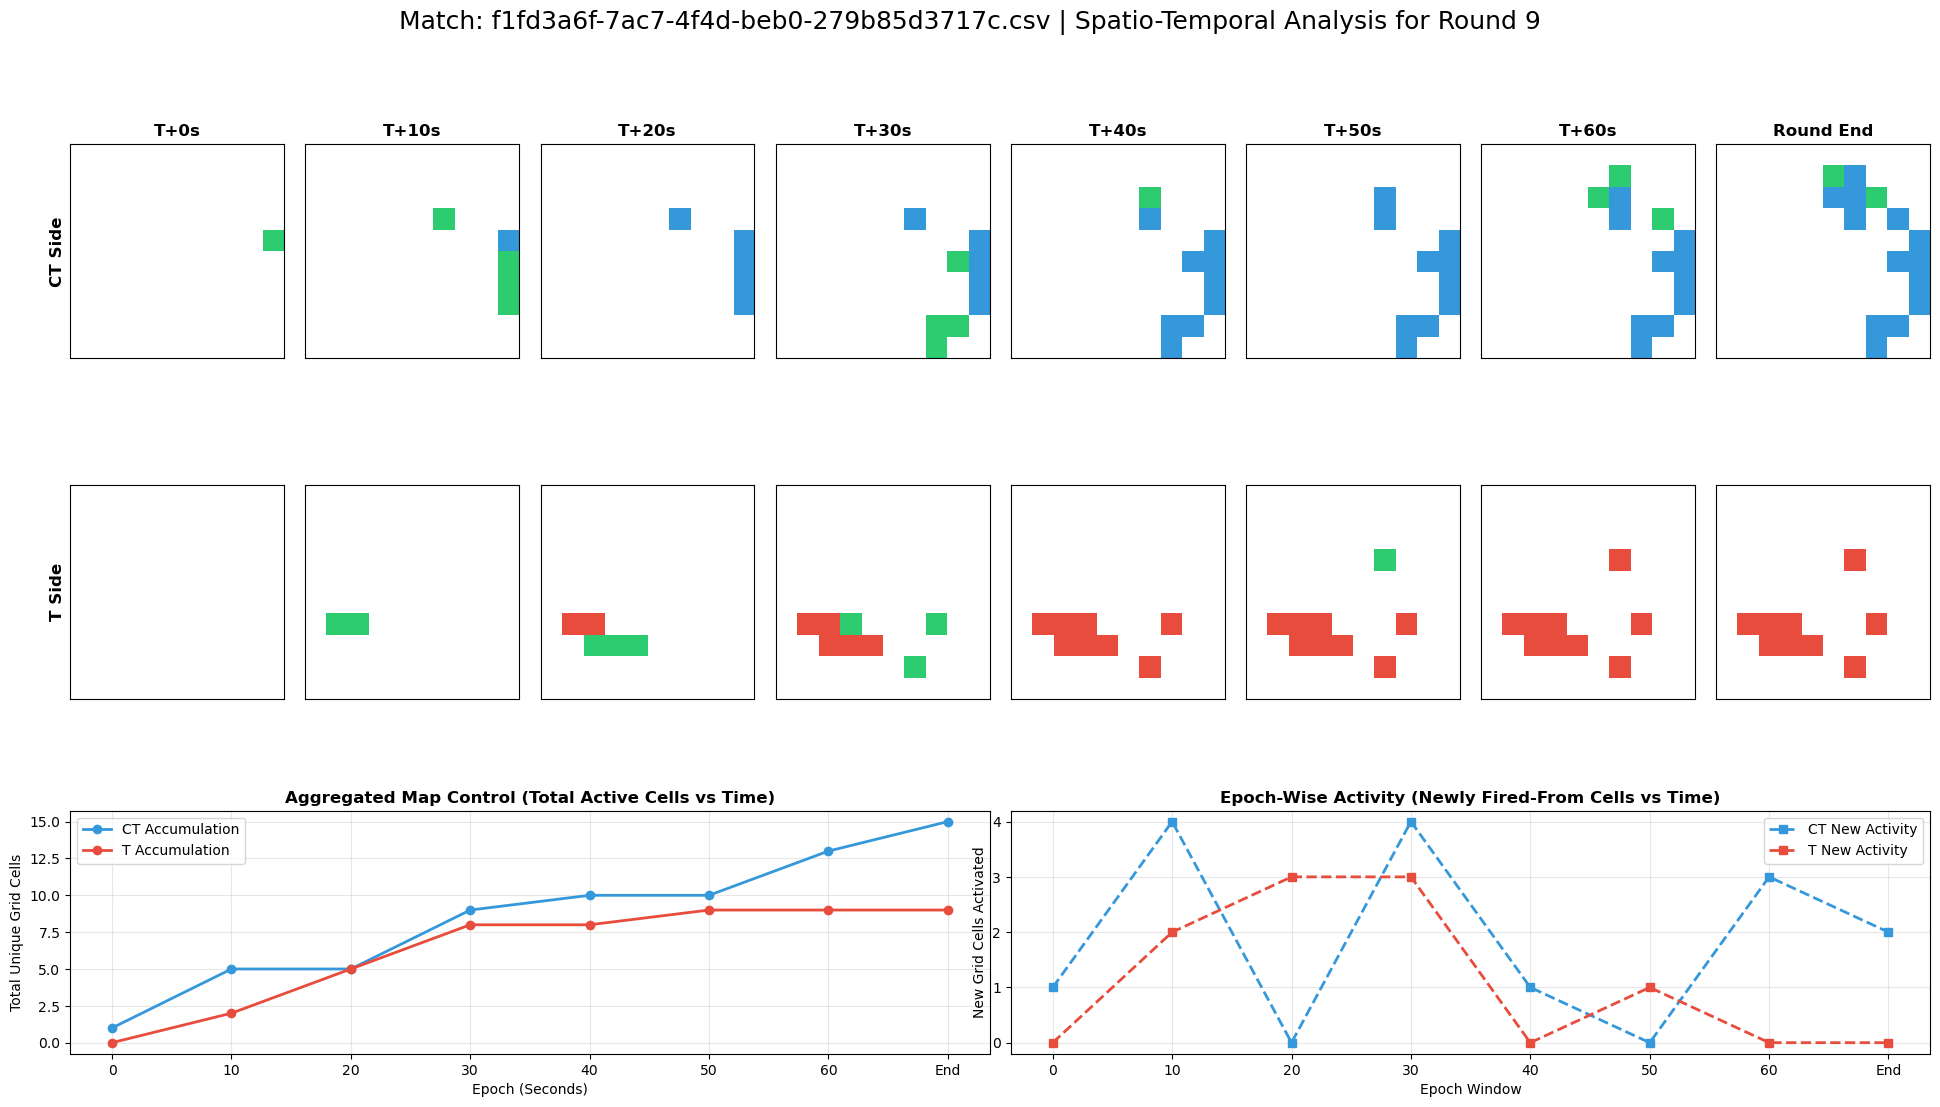

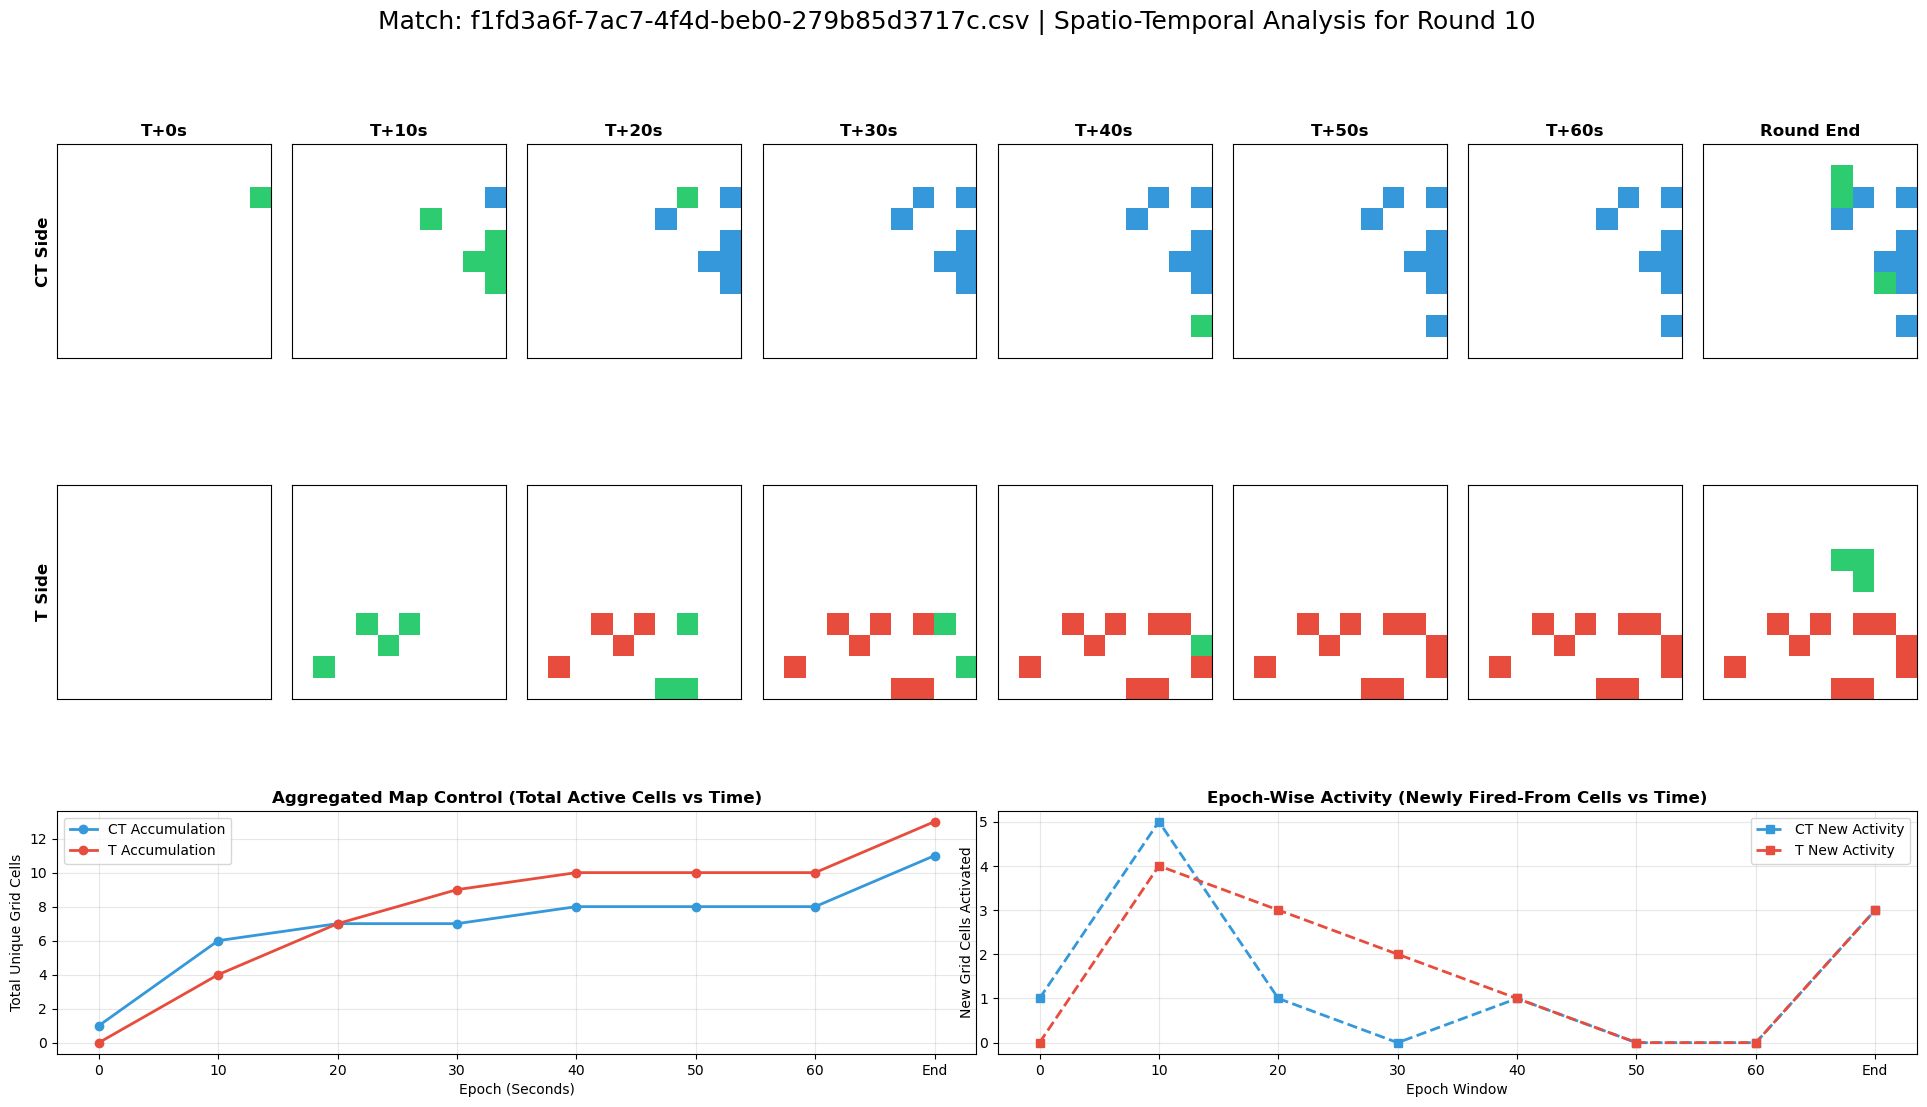

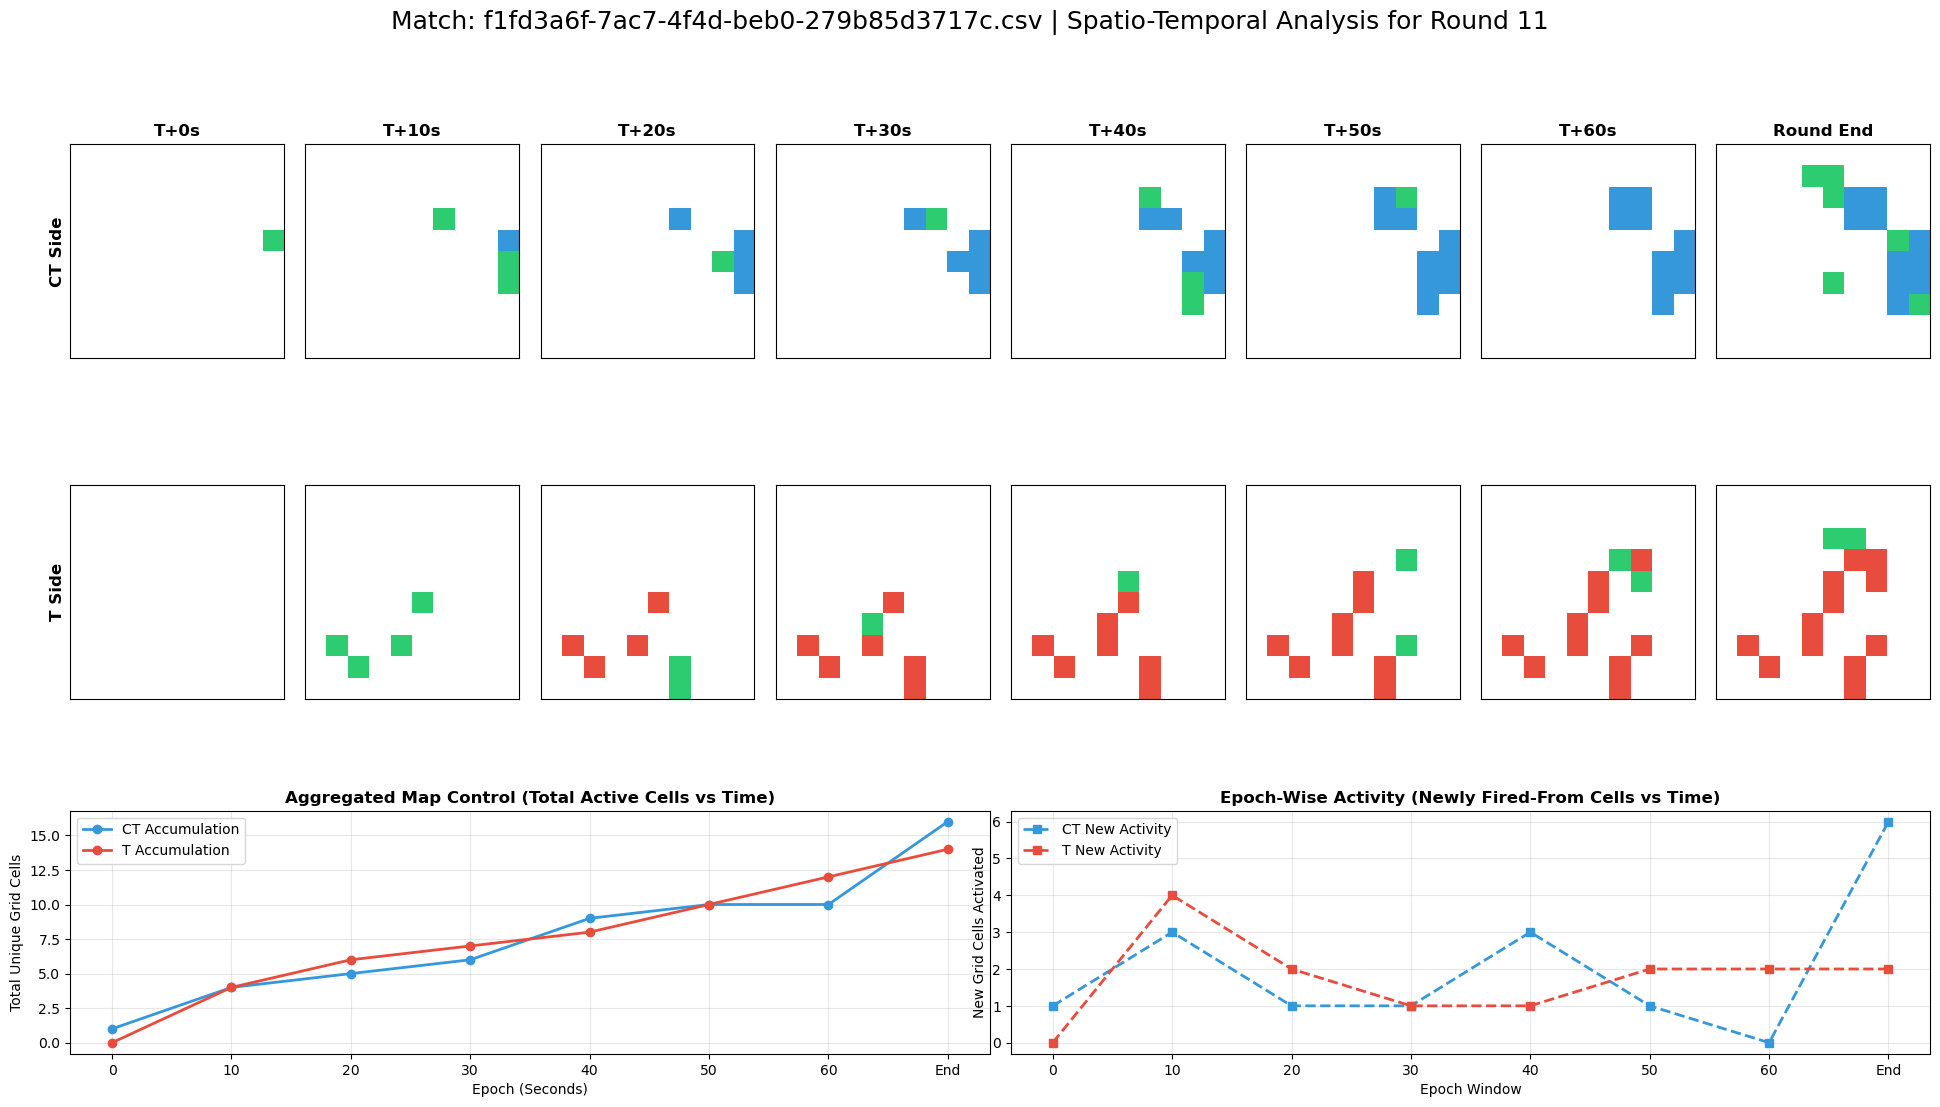

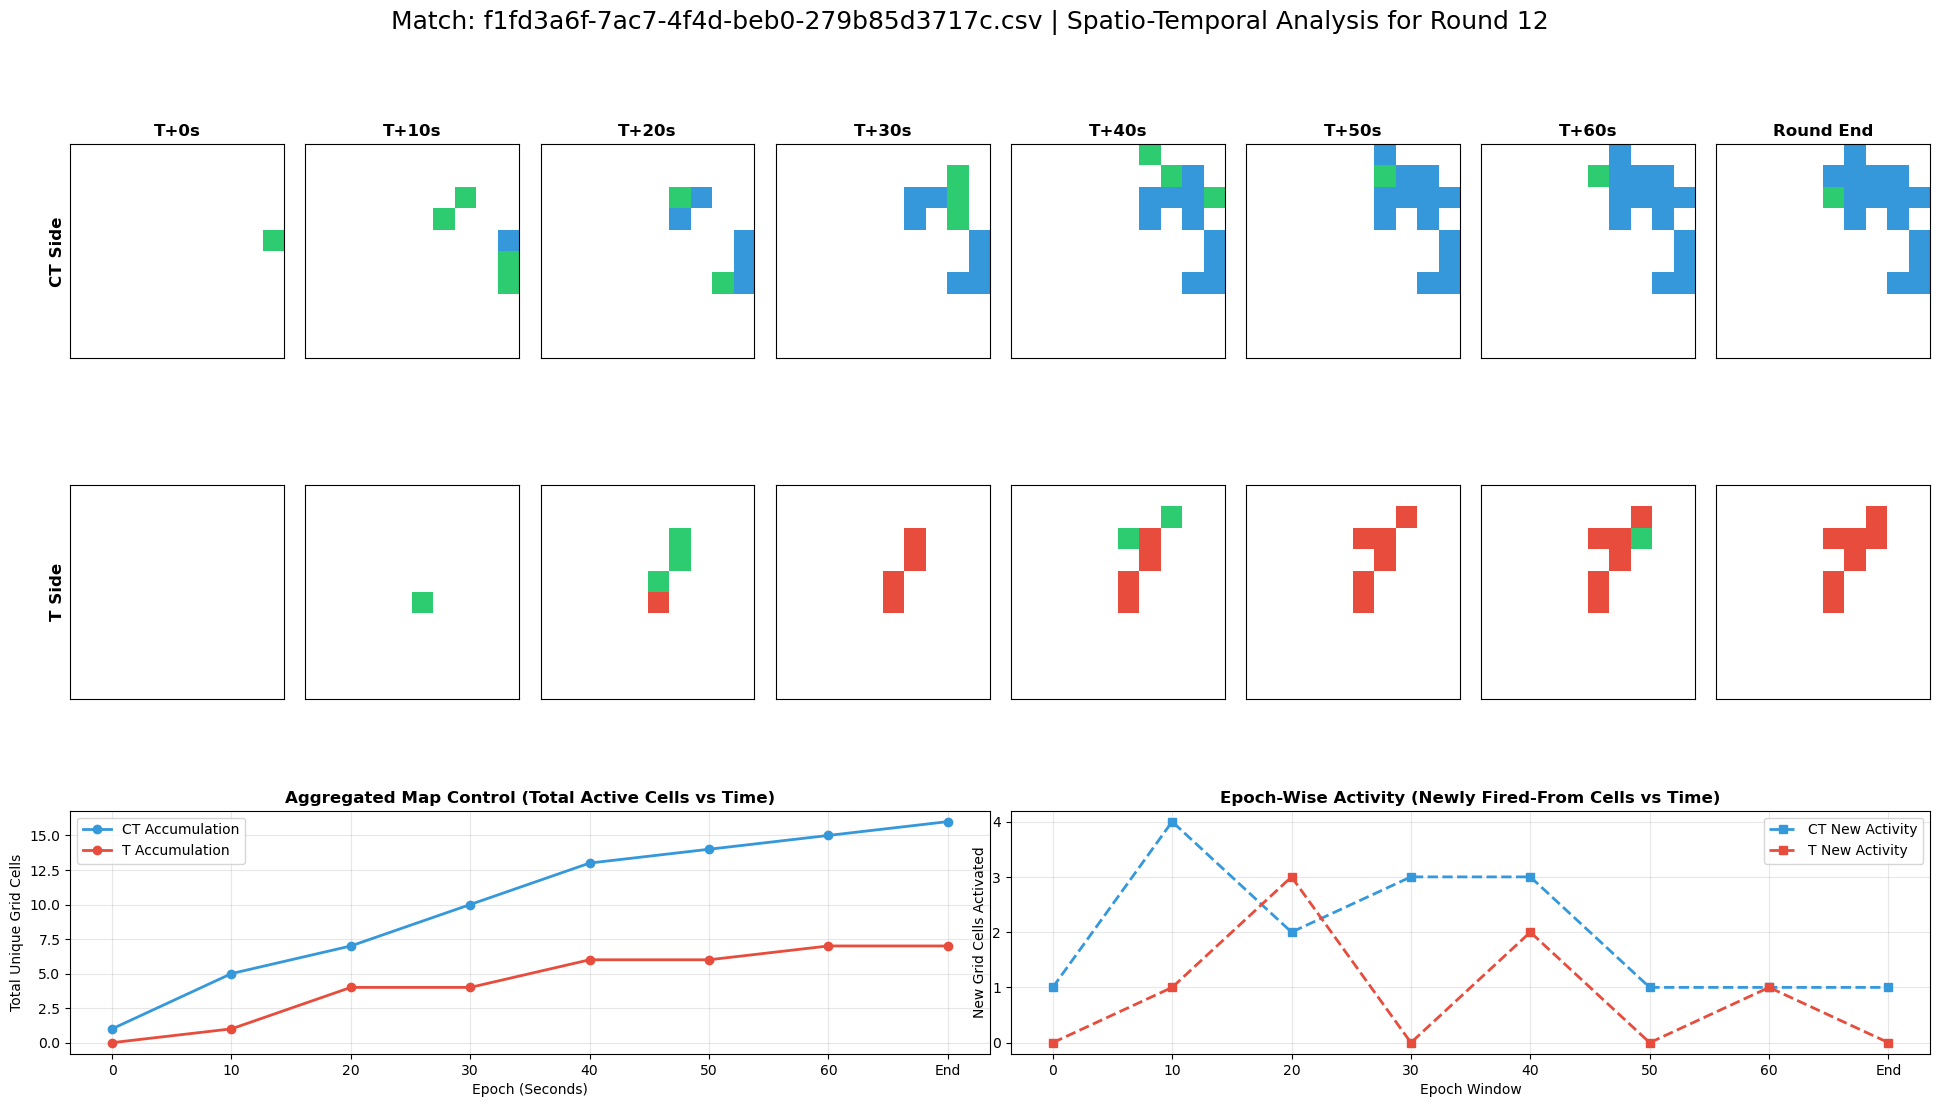

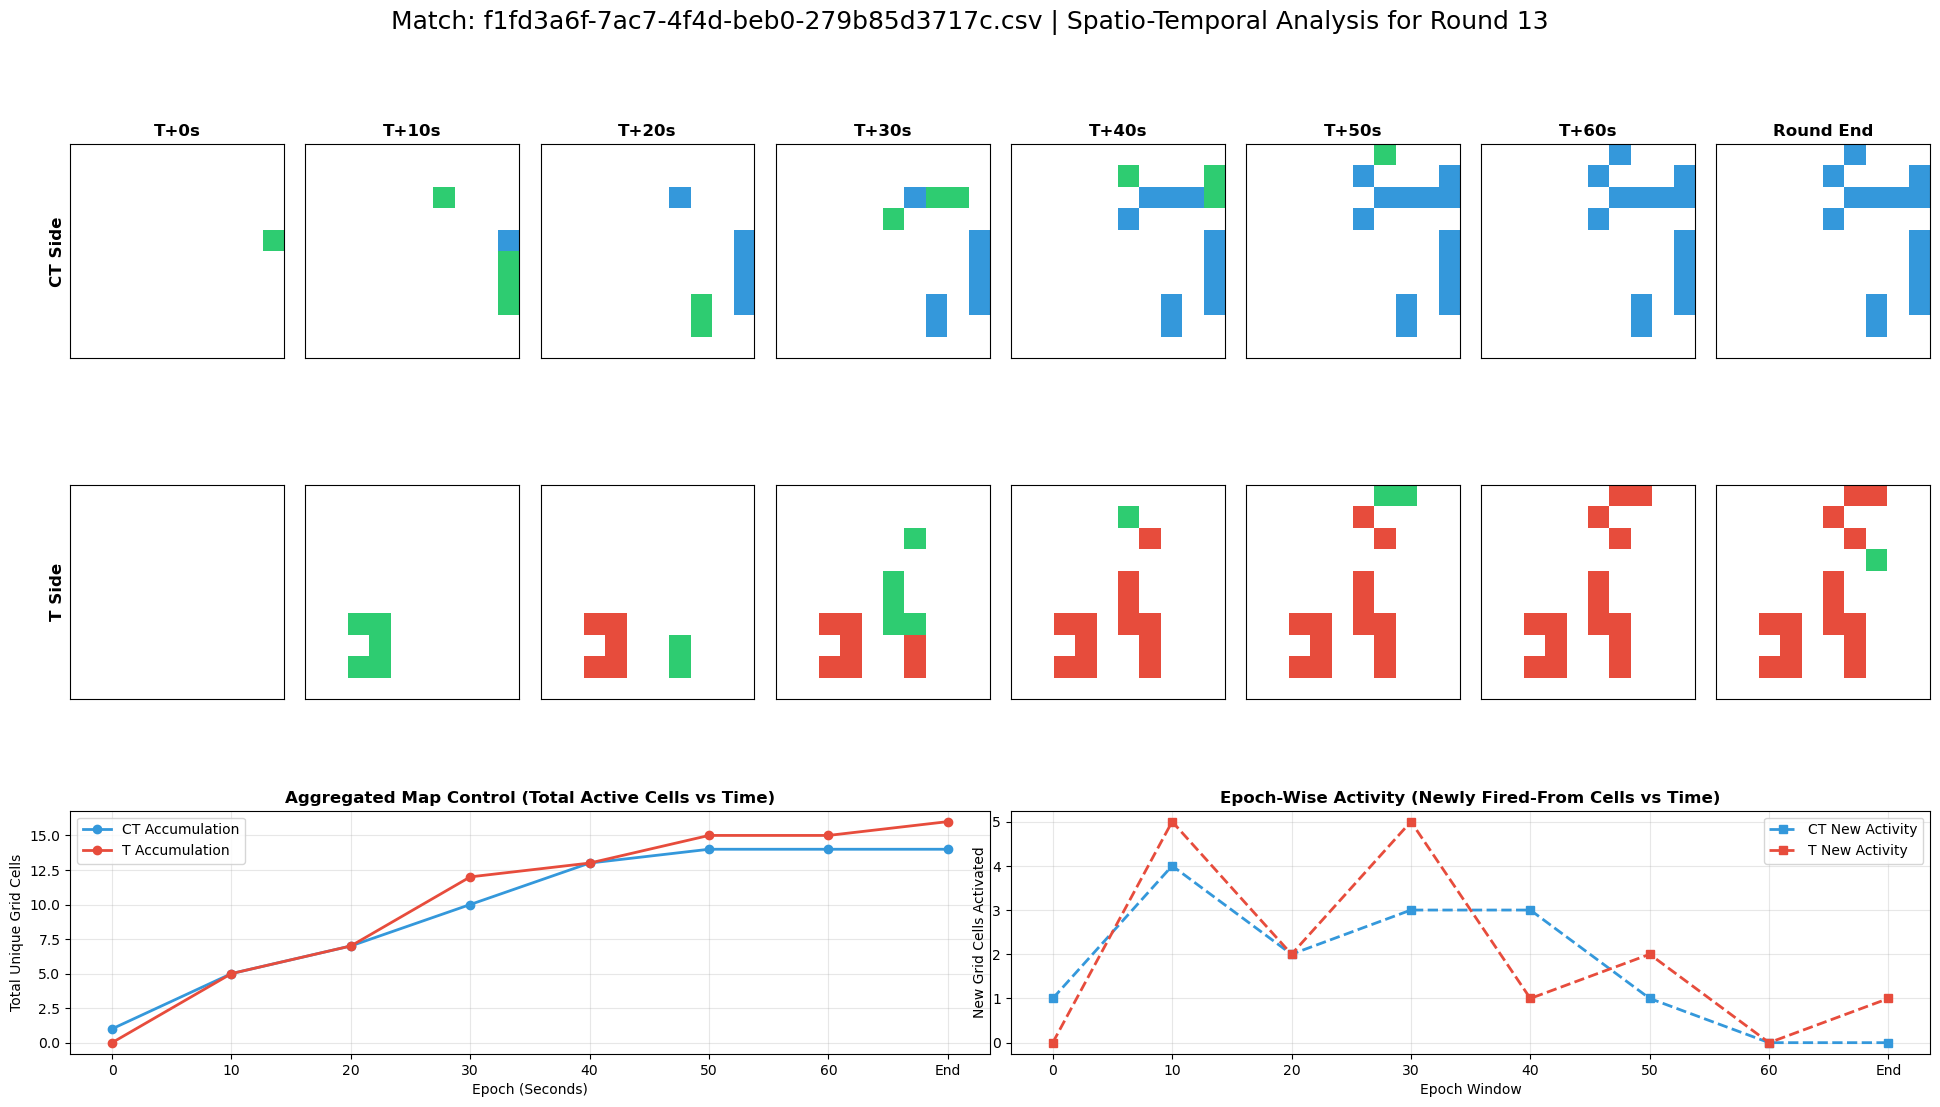

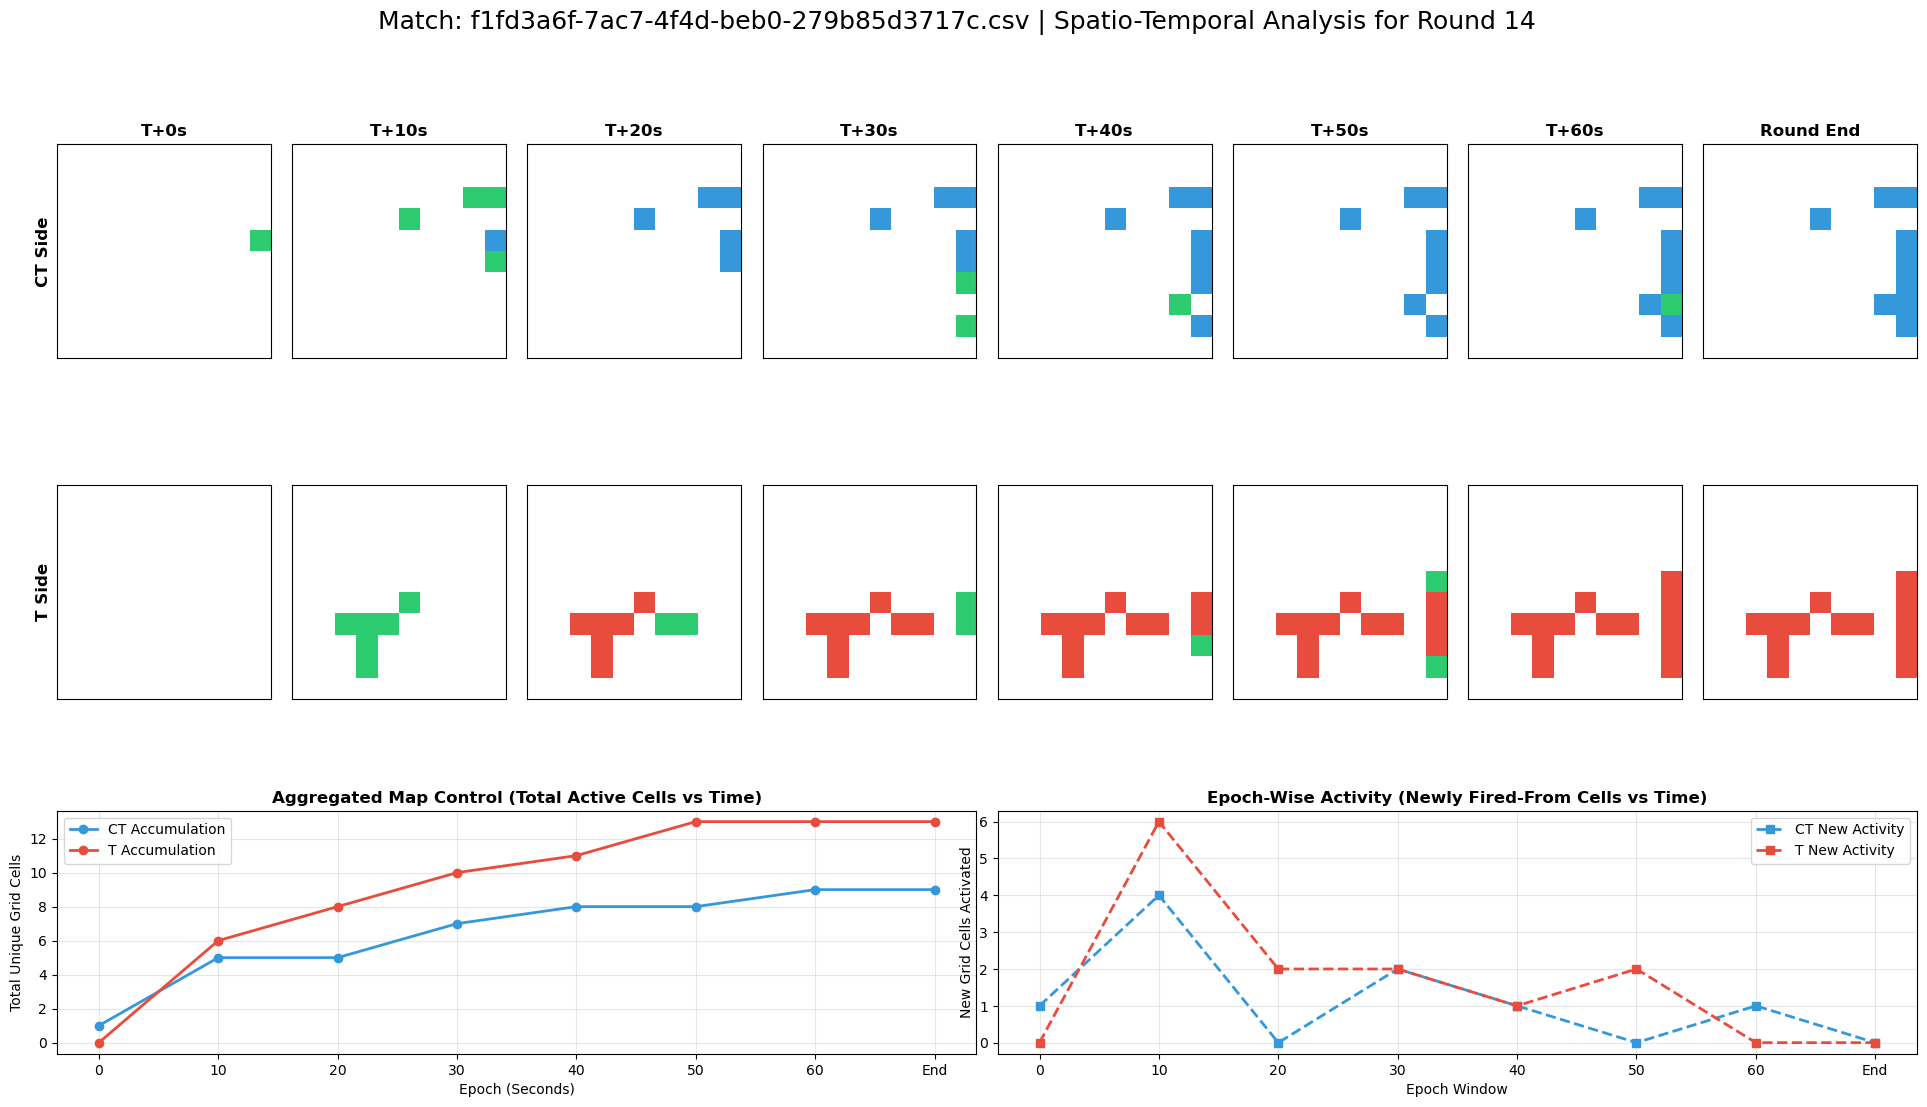

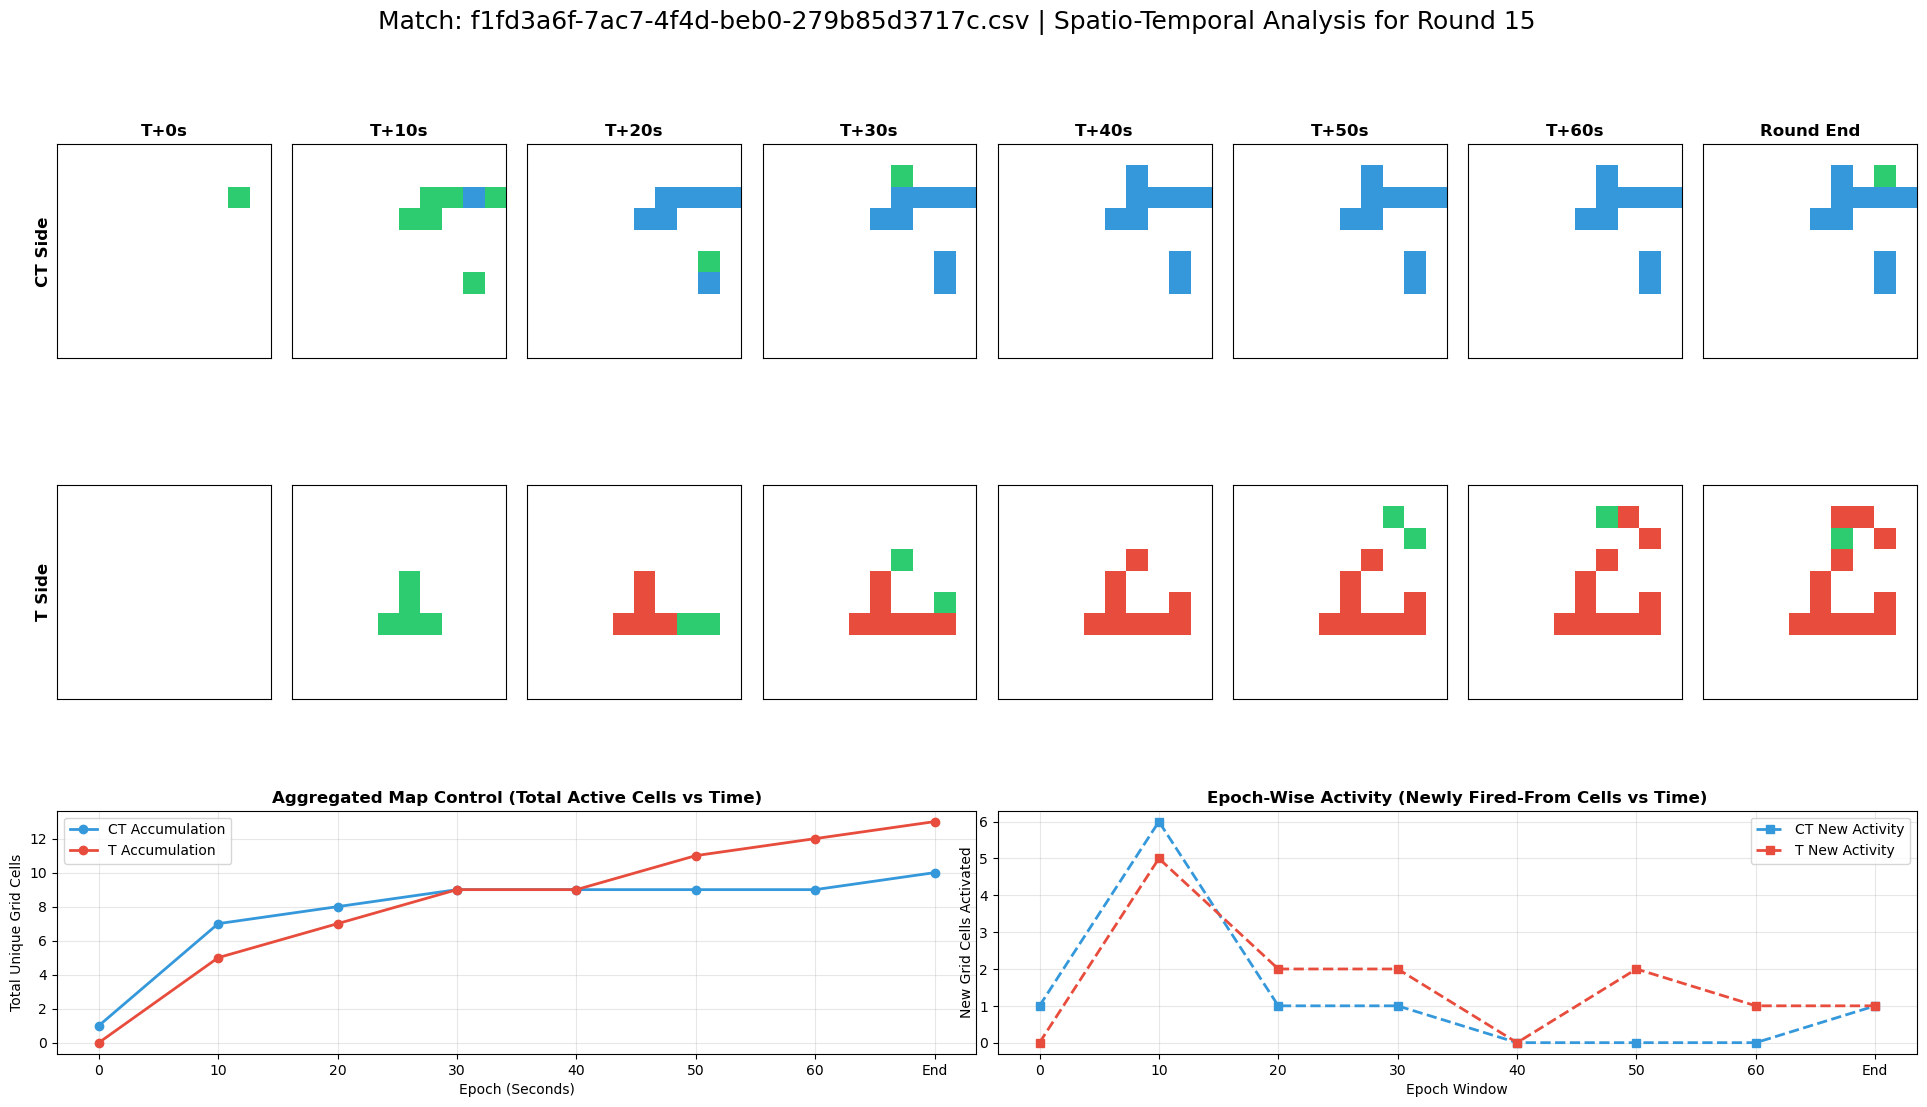

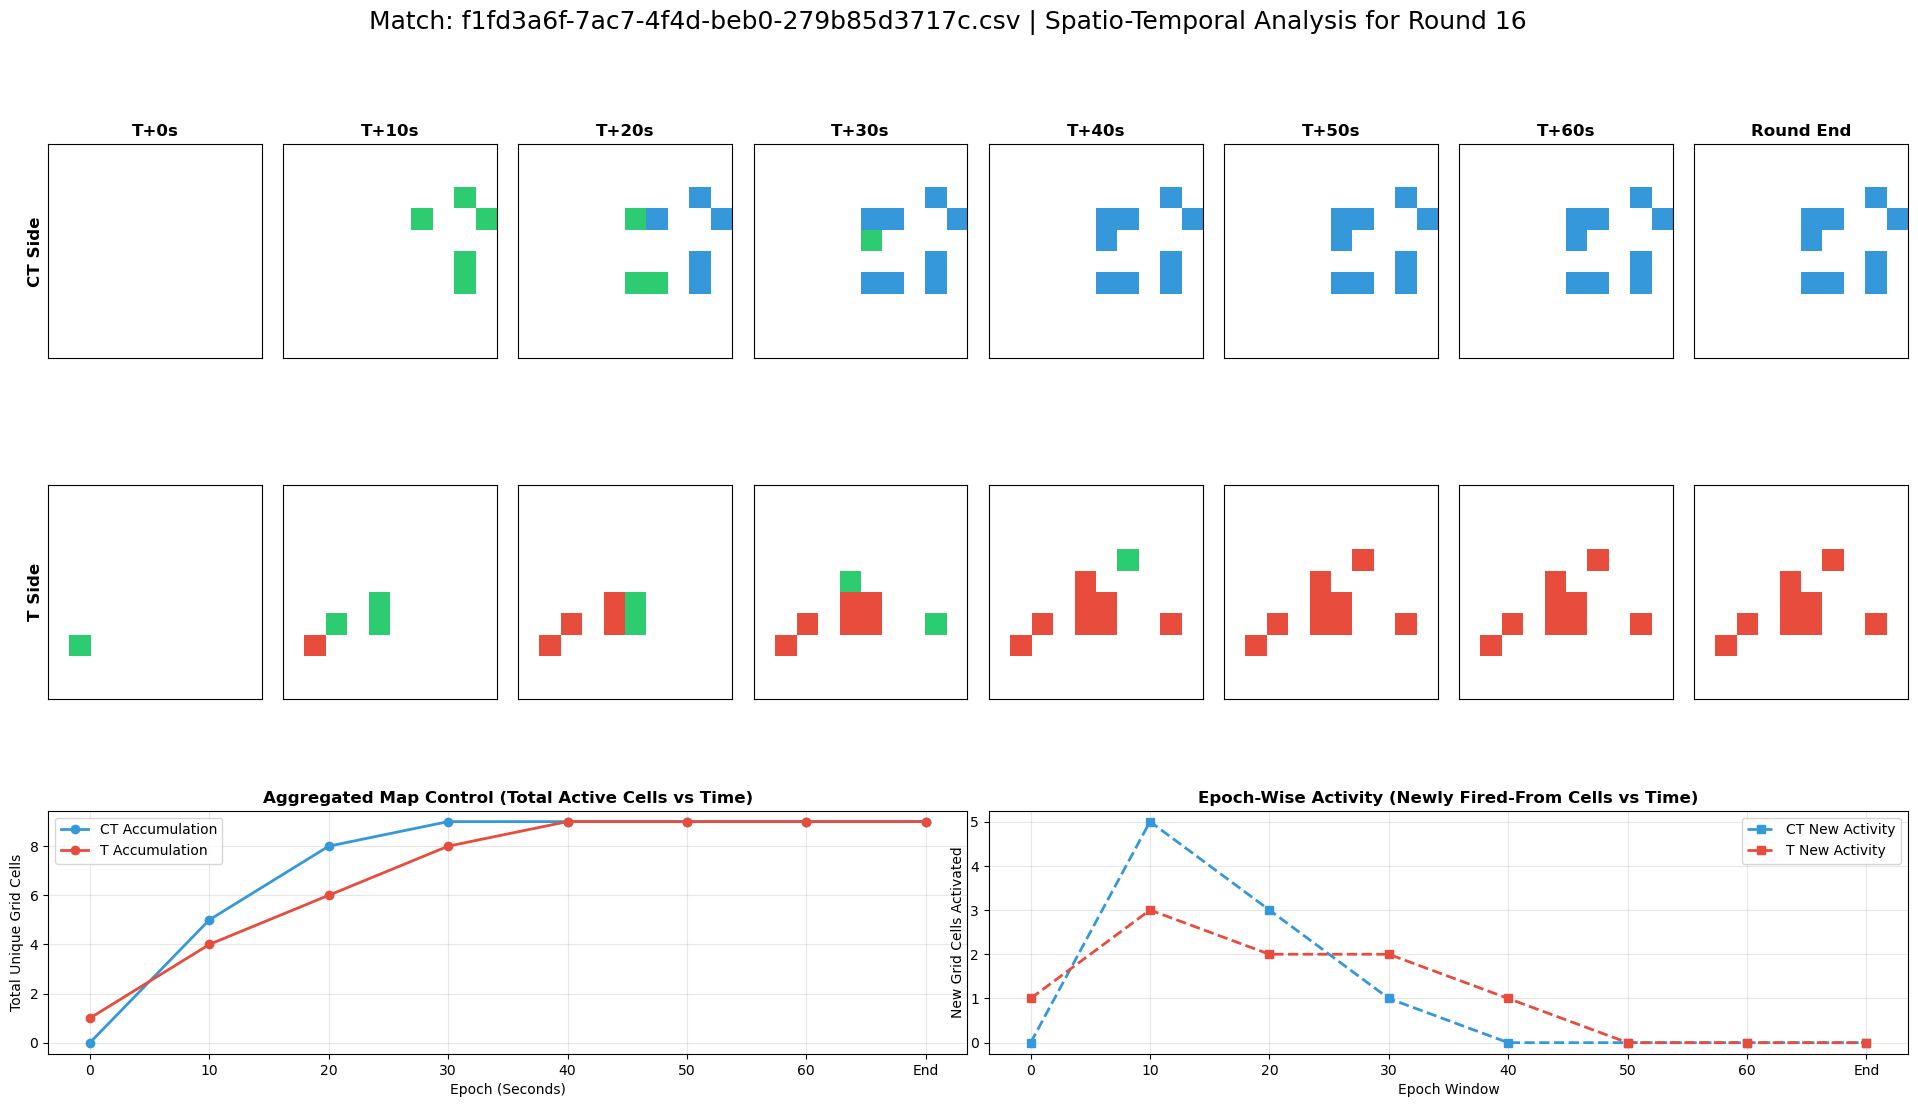

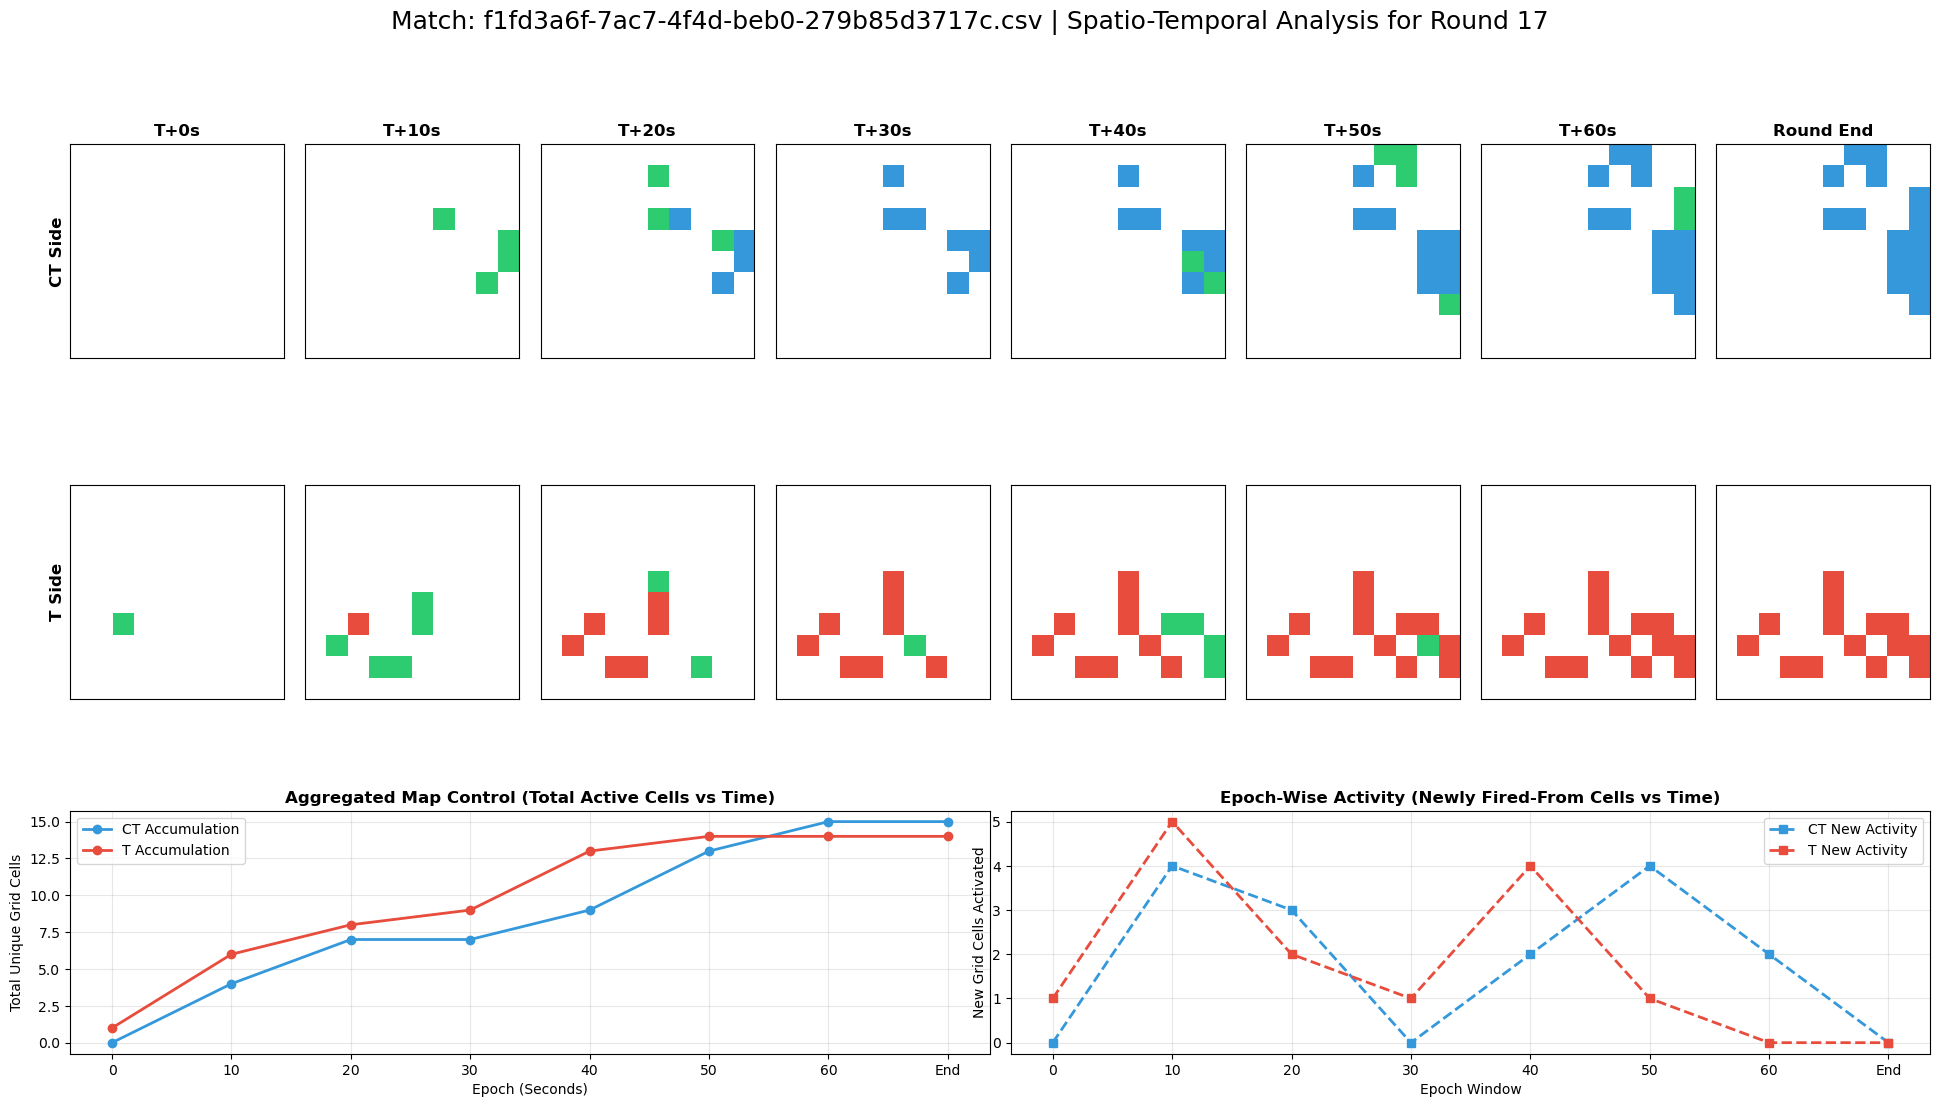

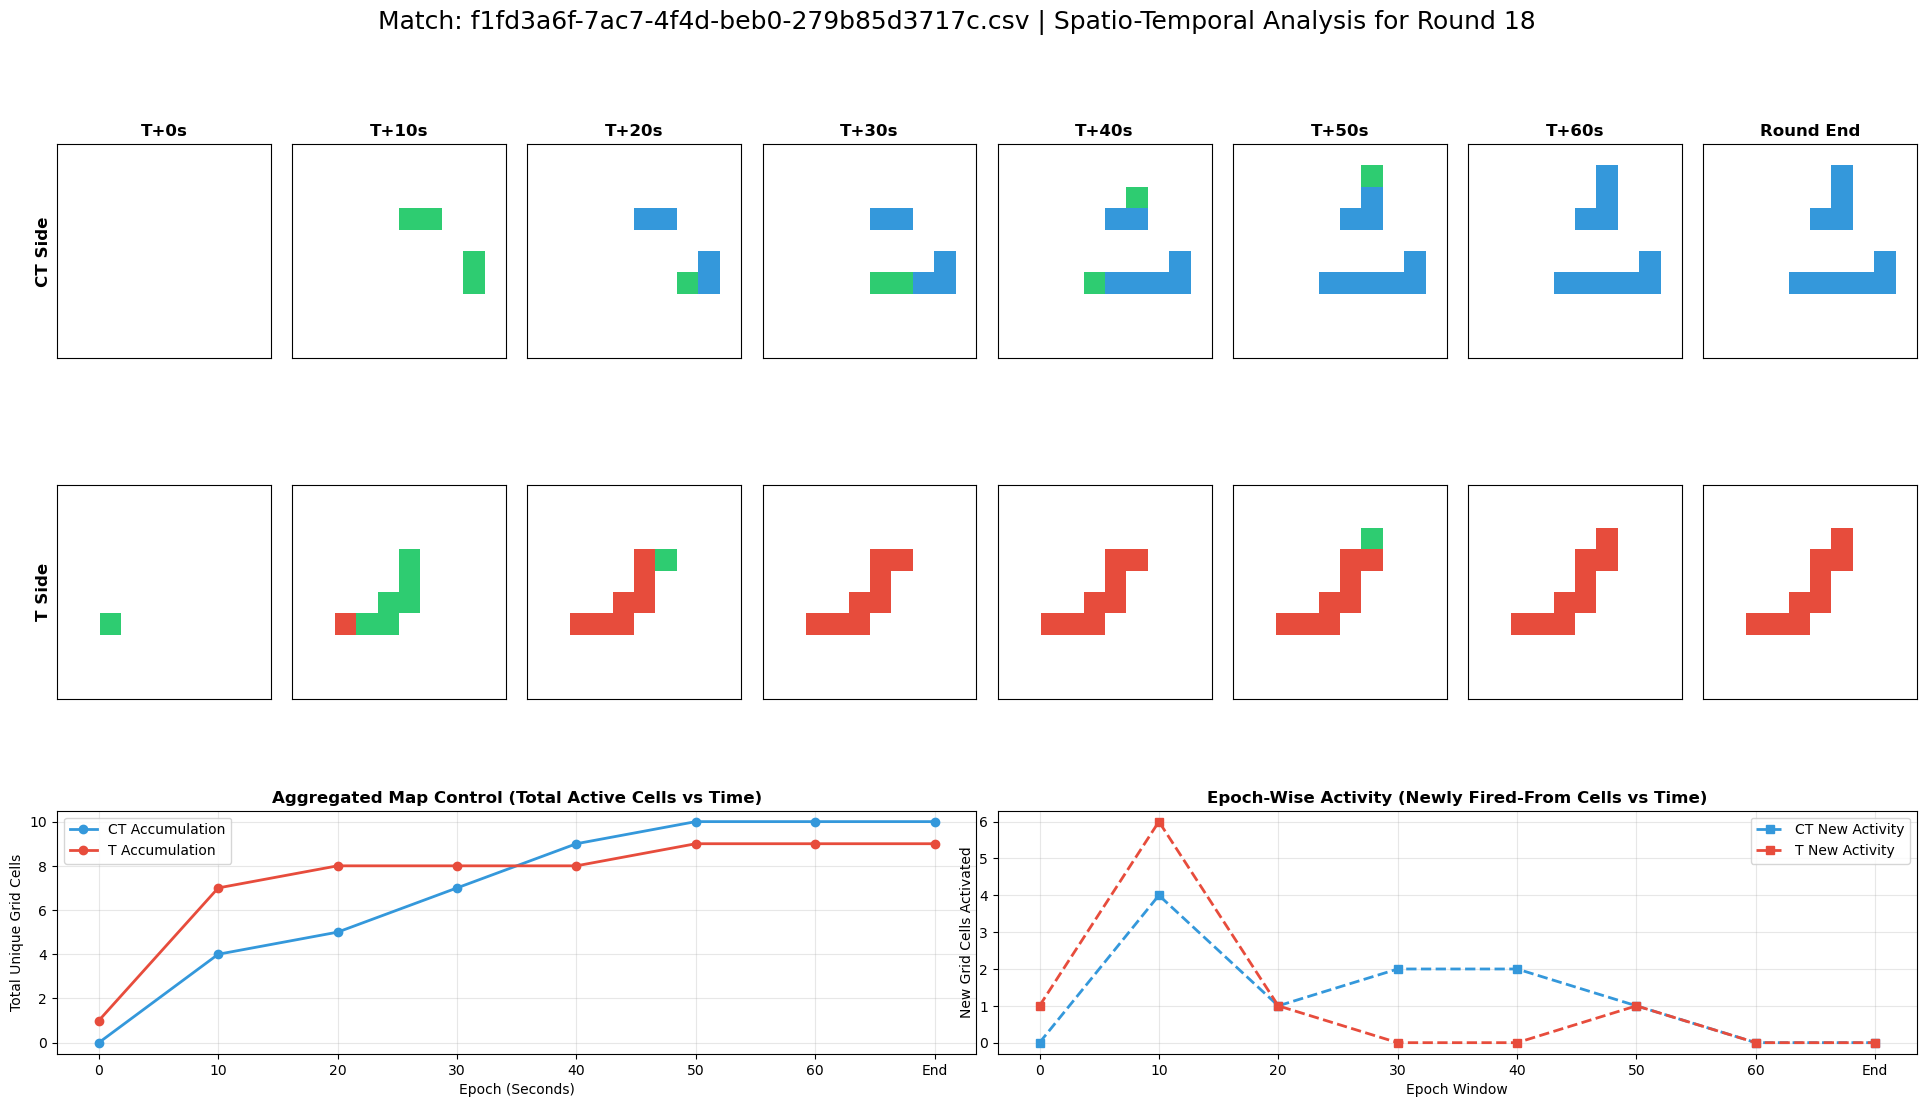

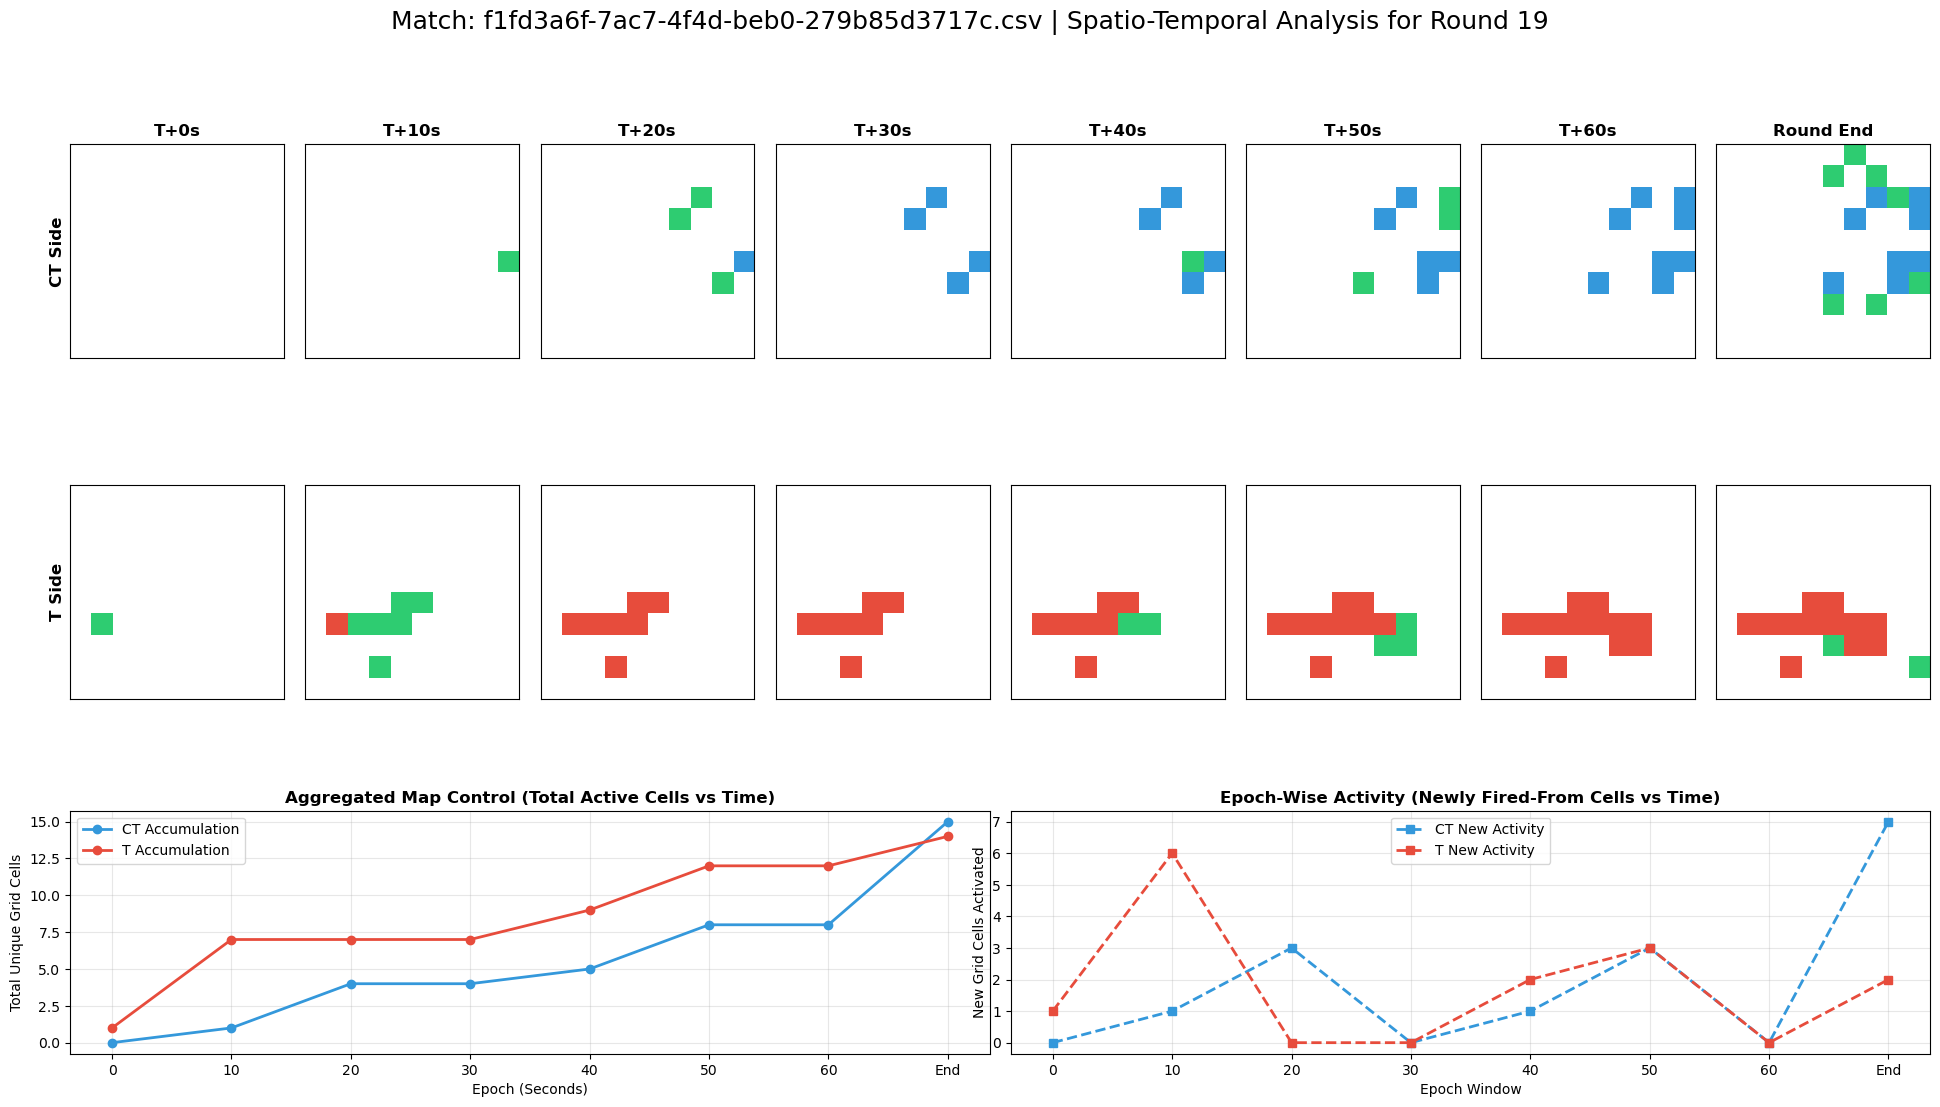

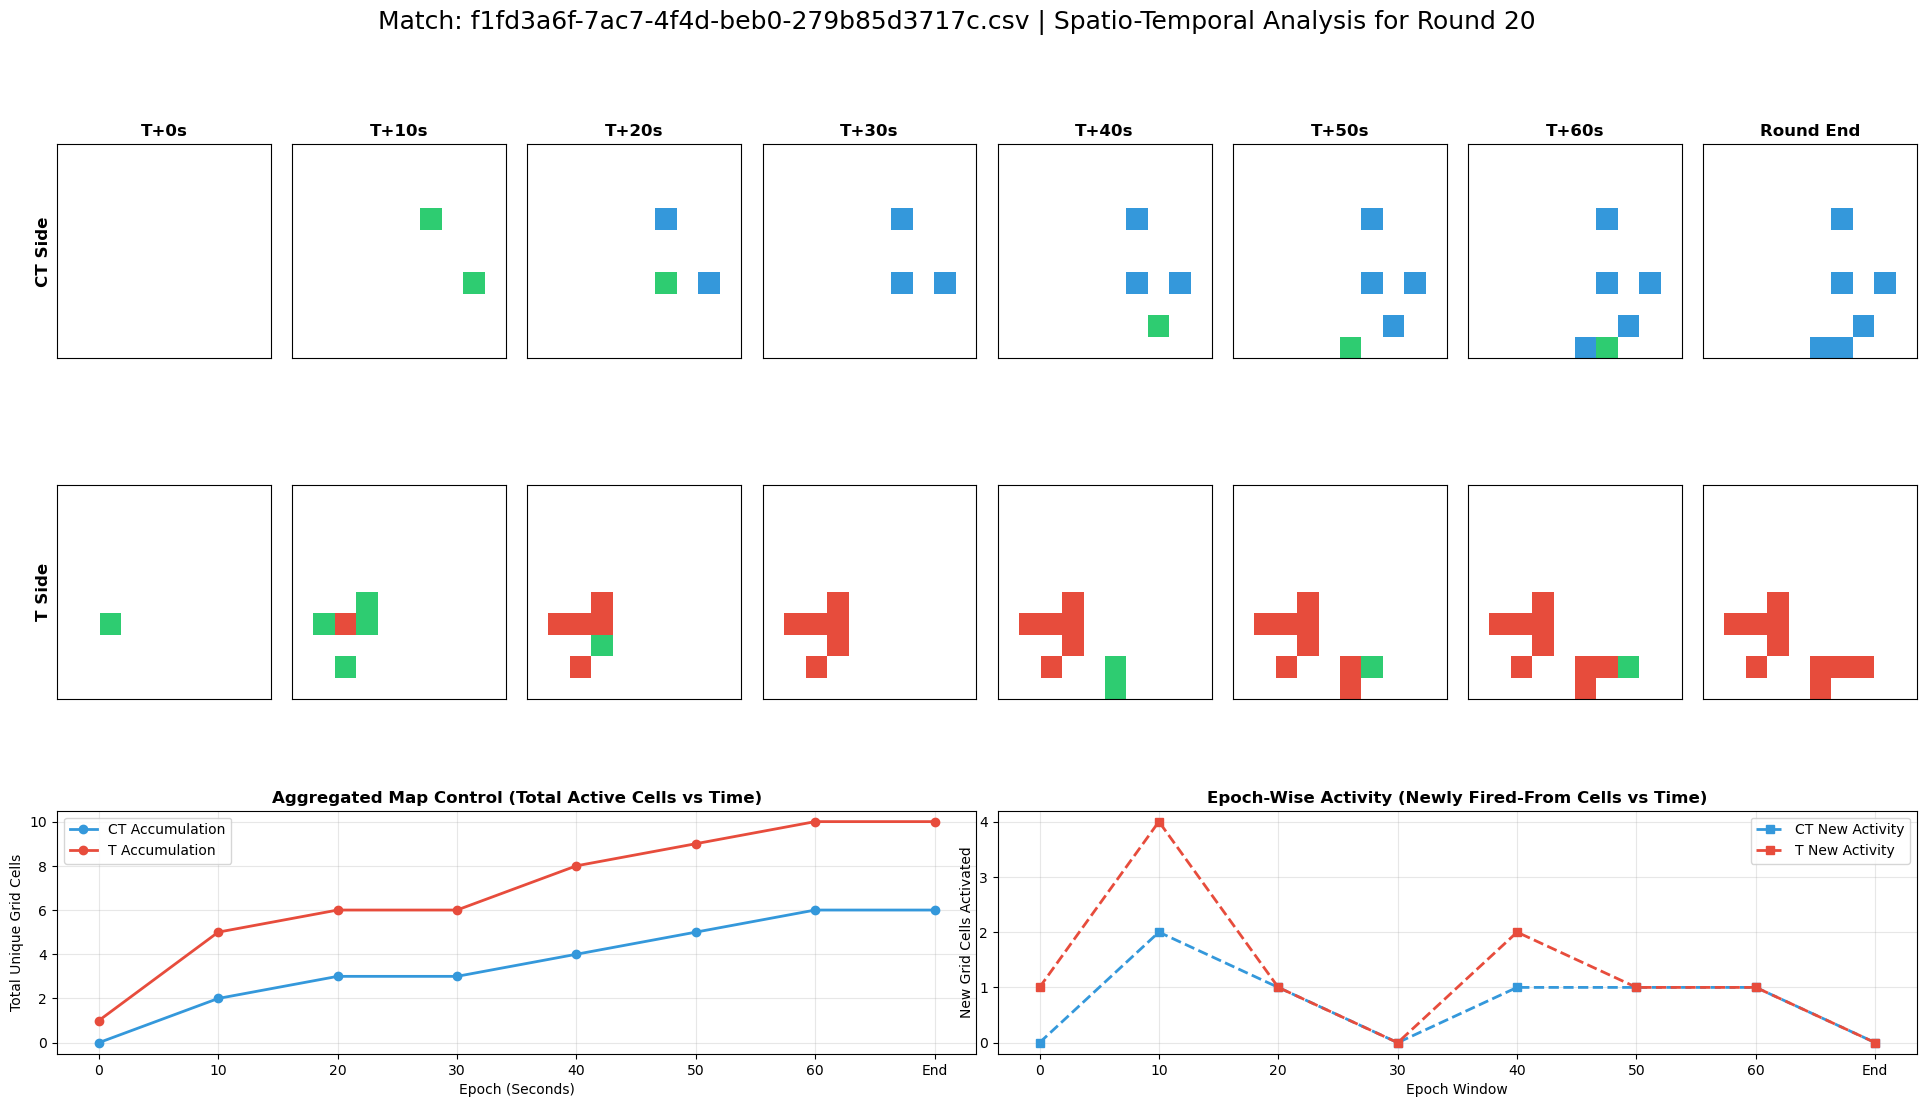

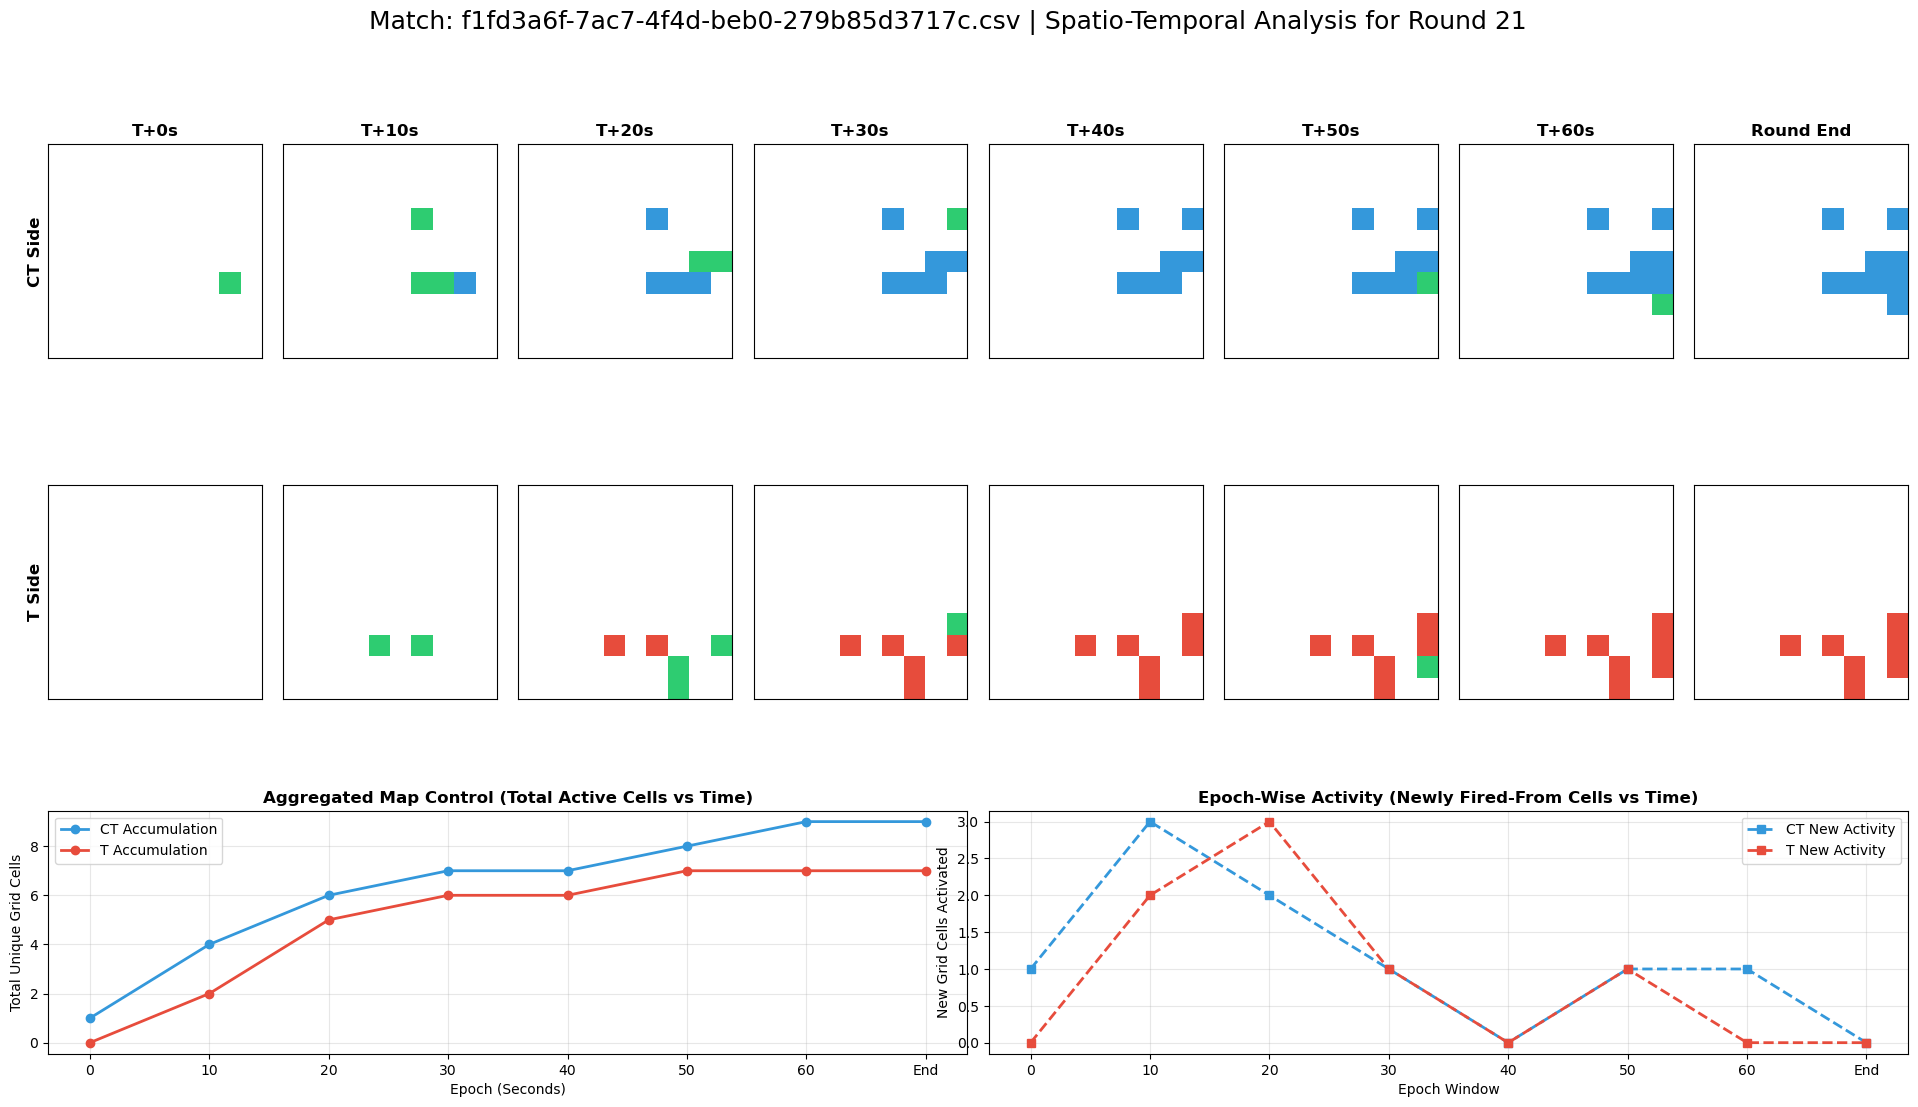

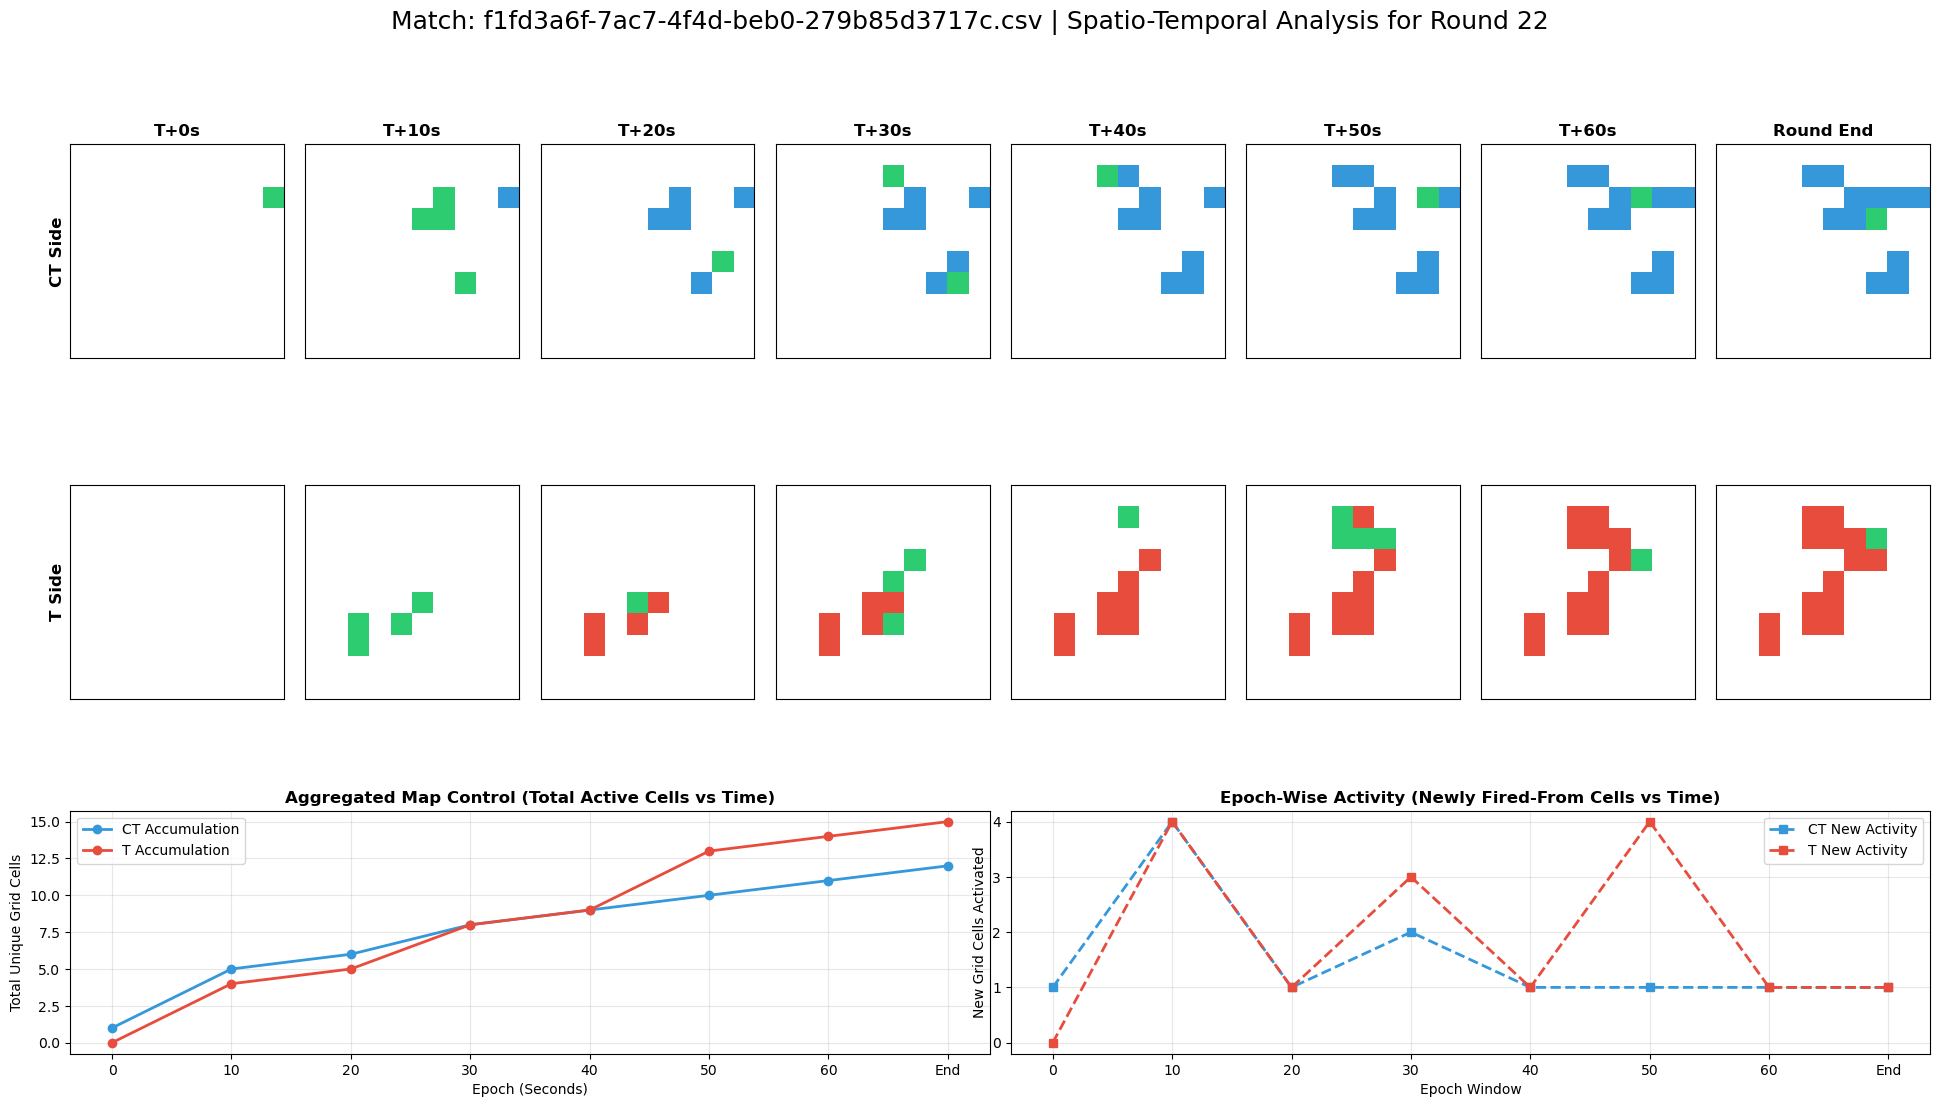

In [3]:
import os
import glob
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.gridspec import GridSpec

# ==========================================
# 1. CONFIGURATION & CONSTANTS
# ==========================================
DATA_DIR = r"F:\Research_Data_Public\Esports\CSDATA\DataScience\CS2_Project\FeatData\Wfire_STOMS_01\Training\Inferno"
EPOCHS = [0, 10, 20, 30, 40, 50, 60, "End"]
GRID_SIZE = 10

# ==========================================
# 2. FEATURE RETRIEVAL & USER SELECTION
# ==========================================
def select_match_file():
    """Lists available matches and prompts the user to select one by index."""
    if not os.path.exists(DATA_DIR):
        print(f"Error: Directory does not exist: {DATA_DIR}")
        return None

    # Find all CSV feature files in the directory
    files = glob.glob(os.path.join(DATA_DIR, "*.csv"))
    if not files:
        print("No CSV feature files found in the specified directory.")
        return None

    print("\n--- Available Matches ---")
    for idx, filepath in enumerate(files):
        print(f"[{idx}] {os.path.basename(filepath)}")

    # Handle user input
    while True:
        try:
            selection = int(input(f"\nEnter the index [0 to {len(files)-1}] of the match to visualize: "))
            if 0 <= selection < len(files):
                return files[selection]
            else:
                print("Invalid index. Please try again.")
        except ValueError:
            print("Please enter a valid number.")

# ==========================================
# 3. DATA PARSING & VISUALIZATION
# ==========================================
def visualize_match_stoms(filepath):
    """Loads the STOM features and visualizes the grids and collapsed metrics per round."""
    print(f"\nLoading data from: {os.path.basename(filepath)}")
    df = pl.read_csv(filepath)
    rounds = df["round"].to_list()

    for r_idx in range(len(rounds)):
        round_data = df.row(r_idx, named=True)
        r_id = round_data["round"]

        # Initialize data structures for collapsed metrics
        # aggregated = total map coverage | epoch_wise = newly fired cells in that window
        aggregated_counts = {"CT": [], "T": []}
        epoch_wise_counts = {"CT": [], "T": []}

        # Setup Figure using GridSpec (3 rows: CT maps, T maps, Line Plots)
        fig = plt.figure(figsize=(24, 12))
        gs = GridSpec(3, len(EPOCHS), figure=fig, hspace=0.4, wspace=0.1)

        # --------------------------------------------------
        # STOM Heatmaps (Rows 0 and 1)
        # --------------------------------------------------
        for side_idx, side in enumerate(["CT", "T"]):
            for epoch_idx, epoch in enumerate(EPOCHS):
                # Retrieve the 100 features for this specific Side and Epoch
                grid = np.zeros((GRID_SIZE, GRID_SIZE), dtype=int)
                for i in range(GRID_SIZE * GRID_SIZE):
                    col_name = f"{side}_e{epoch}_cell_{i:02d}"
                    val = round_data.get(col_name, 0)
                    # Mapping flattened index back to 2D
                    r, c = divmod(i, GRID_SIZE)
                    grid[r, c] = val

                # Compute Collapsed Metrics (0=None, 1=History, 2=New Activity)
                total_cells_active = np.sum(grid > 0)
                new_cells_active = np.sum(grid == 2)
                
                aggregated_counts[side].append(total_cells_active)
                epoch_wise_counts[side].append(new_cells_active)

                # Plot Map
                ax = fig.add_subplot(gs[side_idx, epoch_idx])
                
                team_color = "#3498db" if side == "CT" else "#e74c3c"
                cmap = mcolors.ListedColormap(["#ffffff", team_color, "#2ecc71"]) # White, Team, Green
                
                ax.imshow(grid, cmap=cmap, origin='lower', vmin=0, vmax=2)
                ax.set_xticks([])
                ax.set_yticks([])
                
                if side_idx == 0:
                    ax.set_title(f"T+{epoch}s" if epoch != "End" else "Round End", fontweight='bold')
                if epoch_idx == 0:
                    ax.set_ylabel(f"{side} Side", fontweight='bold', fontsize=12)

        # --------------------------------------------------
        # Spatially Collapsed Maps - Aggregated (Row 2, Left)
        # --------------------------------------------------
        ax_agg = fig.add_subplot(gs[2, :len(EPOCHS)//2])
        x_labels = [str(e) for e in EPOCHS]
        
        ax_agg.plot(x_labels, aggregated_counts["CT"], marker='o', color="#3498db", label="CT Accumulation", linewidth=2)
        ax_agg.plot(x_labels, aggregated_counts["T"], marker='o', color="#e74c3c", label="T Accumulation", linewidth=2)
        ax_agg.set_title("Aggregated Map Control (Total Active Cells vs Time)", fontsize=12, fontweight='bold')
        ax_agg.set_xlabel("Epoch (Seconds)")
        ax_agg.set_ylabel("Total Unique Grid Cells")
        ax_agg.grid(True, alpha=0.3)
        ax_agg.legend()

        # --------------------------------------------------
        # Spatially Collapsed Maps - Epoch-wise (Row 2, Right)
        # --------------------------------------------------
        ax_epoch = fig.add_subplot(gs[2, len(EPOCHS)//2:])
        
        # Undo accumulation - plot only the new cells fired from in the current epoch window
        ax_epoch.plot(x_labels, epoch_wise_counts["CT"], marker='s', color="#3498db", linestyle="--", label="CT New Activity", linewidth=2)
        ax_epoch.plot(x_labels, epoch_wise_counts["T"], marker='s', color="#e74c3c", linestyle="--", label="T New Activity", linewidth=2)
        ax_epoch.set_title("Epoch-Wise Activity (Newly Fired-From Cells vs Time)", fontsize=12, fontweight='bold')
        ax_epoch.set_xlabel("Epoch Window")
        ax_epoch.set_ylabel("New Grid Cells Activated")
        ax_epoch.grid(True, alpha=0.3)
        ax_epoch.legend()

        # Render combined figure
        plt.suptitle(f"Match: {os.path.basename(filepath)} | Spatio-Temporal Analysis for Round {r_id}", fontsize=18, y=0.98)
        plt.show()

# ==========================================
# MAIN EXECUTION
# ==========================================
if __name__ == "__main__":
    selected_file = select_match_file()
    if selected_file:
        visualize_match_stoms(selected_file)